# 7. Test 80/20 models on external validation datasets

This notebook evaluates saved XGB and ENet 80/20 models on external validation datasets.

The evaluation is split into **four independent, highlighted evaluation cells** so the slow work is checkpointed after each model folder finishes:

1. `../results_xgb`
2. `../results_enet`
3. `../res_enet_zbig`
4. `../res_xgb_zbig`

Each evaluation cell saves its own prediction and metric files immediately, then refreshes the combined files in `../results_comparison_all_models/`. This makes the notebook safer to run in pieces: once a section finishes, its results are already on disk.

Main combined outputs for notebook 8 are saved to `../results_comparison_all_models/`:

- `eval_predictions_long.parquet` / `.csv` fallback
- `eval_metrics_by_protein.csv`
- `eval_metrics_by_tissue.csv`
- `model_inventory.csv`
- `feature_coverage.csv`

Per-folder outputs are saved with names like:

- `results_xgb__eval_predictions_long.parquet` / `.csv` fallback
- `results_xgb__eval_metrics_by_protein.csv`
- `results_xgb__feature_coverage.csv`

The follow-up notebook `8.prot_model_val.ipynb` reads the combined saved predictions/metrics and makes the final partition plots.

Each evaluation cell now also saves tissue-level outputs immediately for the model folder that just finished:

- `<source>__eval_metrics_by_tissue.csv`
- `<source>__eval_metrics_by_tissue_tableS6_format.csv`
- `<source>__eval_metrics_by_tissue_protein.csv`

The TableS6-format tissue files keep the same leading columns as Xu `TableS6` in `Table0_S1-S8_Combined20220114.xlsx`, then append model/run metadata. Combined tissue outputs are refreshed from completed source folders in `../results_comparison_all_models/`:

- `eval_metrics_by_tissue.csv`
- `eval_metrics_by_tissue_tableS6_format.csv`
- `eval_metrics_by_tissue_protein.csv` when enabled

A dedicated ENet zbig k5000 tissue-wise export is also written for backwards compatibility with `10.xu_comparison.ipynb`:

- `enet_zbig_k5000_tissue_metrics.csv`
- `enet_zbig_k5000_tissue_protein_metrics.csv`
- `enet_zbig_k5000_tissue_metrics_xu_format.csv`


In [1]:
# Shared validation utilities
from pathlib import Path as _Path
import sys as _sys

# Make `src/utils_val.py` importable whether the kernel starts in the notebook
# folder, the project root, or a sibling notebook folder such as notebooks2.
_src_search_roots = []
_cwd = _Path.cwd().resolve()
for _base in [_cwd, *_cwd.parents]:
    for _candidate in [_base, _base / "notebooks", _base / "notebooks2"]:
        if _candidate not in _src_search_roots:
            _src_search_roots.append(_candidate)

for _candidate in _src_search_roots:
    if (_candidate / "src" / "utils_val.py").exists():
        if str(_candidate) not in _sys.path:
            _sys.path.insert(0, str(_candidate))
        print("Using validation utilities from:", _candidate / "src" / "utils_val.py")
        break
else:
    raise FileNotFoundError(
        "Could not find src/utils_val.py. Put this notebook in the project/notebooks2 folder "
        "or keep a src/utils_val.py folder next to the notebook."
    )

import src.utils_val as uv
from src.utils_val import *

# Backward-compatible global sync. Extracted functions in src.utils_val resolve
# globals inside the utils_val module, so notebook paths/dataframes need to be
# pushed there after config/data/model cells run.
def sync_utils_globals(namespace=None, **kwargs):
    ns = globals() if namespace is None else namespace
    clean = {}
    for _name, _value in dict(ns).items():
        if str(_name).startswith("__"):
            continue
        clean[_name] = _value
    clean.update(kwargs)

    if hasattr(uv, "configure_runtime_globals"):
        uv.configure_runtime_globals(**clean)
    elif hasattr(uv, "set_module_globals"):
        try:
            uv.set_module_globals(clean)
        except TypeError:
            uv.set_module_globals(**clean)
    else:
        for _name, _value in clean.items():
            setattr(uv, _name, _value)
    return None

sync_utils_globals()


Using validation utilities from: C:\Users\hp\Desktop\new_pRNA\notebooks2\src\utils_val.py


In [2]:
import os
import re
import sys
import json
import glob
import lzma
import pickle
import warnings
from pathlib import Path

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from scipy.spatial.distance import cosine
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# Fix for loading numpy 2.0 pickles in numpy 1.x environments.
try:
    import numpy.core.numeric
    import numpy.core.multiarray
    sys.modules["numpy._core"] = sys.modules.get("numpy.core")
    sys.modules["numpy._core.numeric"] = numpy.core.numeric
    sys.modules["numpy._core.multiarray"] = numpy.core.multiarray
except Exception:
    pass

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})


In [3]:
# ============================================================
# Configuration
# ============================================================

# Robust project-root detection. This lets the notebook run from either the
# repository root or a notebook folder such as notebooks / notebooks2.
CWD = Path.cwd().resolve()
PROJECT_MARKERS = [
    "val_data",
    "processed_data",
    "results_comparison_all_models",
    "res_enet_zbig",
    "results_xgb",
    "Table0_S1-S8_Combined20220114.xlsx",
]

def _candidate_score(path: Path) -> int:
    return sum((path / marker).exists() for marker in PROJECT_MARKERS)

_candidates = []
for p in [CWD, *CWD.parents]:
    if p.exists() and p not in _candidates:
        _candidates.append(p)
ROOT_DIR = max(_candidates, key=_candidate_score)

VAL_DATA_DIR = ROOT_DIR / "val_data"
OUTPUT_DIR = ROOT_DIR / "results_comparison_all_models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Keys are intentionally the folder-style names requested for split evaluation.
MODEL_DIRS = {
    "results_xgb": ROOT_DIR / "results_xgb",
    "results_enet": ROOT_DIR / "results_enet",
    "res_enet_zbig": ROOT_DIR / "res_enet_zbig",
    "res_xgb_zbig": ROOT_DIR / "res_xgb_zbig",
}

EVALUATION_ORDER = [
    "results_xgb",
    "results_enet",
    "res_enet_zbig",
    "res_xgb_zbig",
]

# Expected validation dataset prefixes. The notebook will skip missing prefixes gracefully.
DATASET_PREFIXES = ["LabelFree", "iTRAQ", "TMT"]

# Set to an integer for a quick smoke test; set to None for full evaluation.
MAX_MODELS_TOTAL = None
MAX_MODELS_PER_FOLDER = None

# If saved per-folder predictions already exist, set this to False to reload instead of recomputing.
FORCE_REEVALUATE = False

# Fast mode: keep per-folder protein/prediction checkpoints exactly as before,
# but avoid rebuilding the huge all-model prediction table after every source.
# Set BUILD_FULL_COMBINED_PREDICTIONS=True only when a downstream notebook
# explicitly needs results_comparison_all_models/eval_predictions_long.parquet.
REFRESH_COMBINED_METRICS_AFTER_EACH_SOURCE = True
BUILD_FULL_COMBINED_PREDICTIONS = False
BUILD_ALL_MODEL_TISSUE_METRICS = False
SAVE_ENET_ZBIG_TISSUE_PROTEIN_METRICS = True
SAVE_COMBINED_TISSUE_PROTEIN_METRICS = False

# When running the refresh section, recompute tissue metrics from existing
# per-source prediction checkpoints. This fixes old numeric ShortName rows
# without rerunning the H5 model evaluation.
REBUILD_TISSUE_METRICS_FROM_SAVED_PREDICTIONS_ON_REFRESH = True
REBUILD_TISSUE_METRICS_FROM_PREDICTION_CHECKPOINTS = True

# Combined output paths used by downstream notebooks.
PREDICTIONS_PARQUET = OUTPUT_DIR / "eval_predictions_long.parquet"
PREDICTIONS_CSV = OUTPUT_DIR / "eval_predictions_long.csv"
METRICS_PROTEIN_CSV = OUTPUT_DIR / "eval_metrics_by_protein.csv"
METRICS_TISSUE_CSV = OUTPUT_DIR / "eval_metrics_by_tissue.csv"
METRICS_TISSUE_XU_FORMAT_CSV = OUTPUT_DIR / "eval_metrics_by_tissue_tableS6_format.csv"
METRICS_TISSUE_PROTEIN_CSV = OUTPUT_DIR / "eval_metrics_by_tissue_protein.csv"
MODEL_INVENTORY_CSV = OUTPUT_DIR / "model_inventory.csv"
FEATURE_COVERAGE_CSV = OUTPUT_DIR / "feature_coverage.csv"

# Xu-comparison outputs generated by the ENet zbig k5000 tissue-wise section.
ENET_ZBIG_TISSUE_CSV = OUTPUT_DIR / "enet_zbig_k5000_tissue_metrics.csv"
ENET_ZBIG_TISSUE_PROTEIN_CSV = OUTPUT_DIR / "enet_zbig_k5000_tissue_protein_metrics.csv"
ENET_ZBIG_XU_FORMAT_CSV = OUTPUT_DIR / "enet_zbig_k5000_tissue_metrics_xu_format.csv"

print("Current working directory:", CWD)
print("Detected project root:", ROOT_DIR)
print("Validation data directory:", VAL_DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Model directories:")
for label, folder in MODEL_DIRS.items():
    print(f"- {label:14s}: {folder} exists={folder.exists()}")

sync_utils_globals()


Current working directory: C:\Users\hp\Desktop\new_pRNA\notebooks2
Detected project root: C:\Users\hp\Desktop\new_pRNA
Validation data directory: C:\Users\hp\Desktop\new_pRNA\val_data
Output directory: C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models
Model directories:
- results_xgb   : C:\Users\hp\Desktop\new_pRNA\results_xgb exists=True
- results_enet  : C:\Users\hp\Desktop\new_pRNA\results_enet exists=True
- res_enet_zbig : C:\Users\hp\Desktop\new_pRNA\res_enet_zbig exists=True
- res_xgb_zbig  : C:\Users\hp\Desktop\new_pRNA\res_xgb_zbig exists=True


## 1. Load external validation datasets

In [4]:
datasets = {}
for prefix in DATASET_PREFIXES:
    loaded = load_val_data(prefix)
    if loaded is not None:
        datasets[prefix] = loaded

if not datasets:
    raise FileNotFoundError("No validation datasets were loaded. Check VAL_DATA_DIR and DATASET_PREFIXES.")

print("\nDatasets loaded:", list(datasets.keys()))

sync_utils_globals()


Loaded LabelFree : X=(360, 11822), Y=(360, 2155), common samples=360
Loaded iTRAQ     : X=(276, 11822), Y=(276, 2155), common samples=276
Loaded TMT       : X=(1924, 11822), Y=(1924, 2155), common samples=1924

Datasets loaded: ['LabelFree', 'iTRAQ', 'TMT']


## 2. Discover model H5 files

In [5]:
model_files = []
for source_label, folder in MODEL_DIRS.items():
    files = sorted(folder.glob("*.h5")) if folder.exists() else []
    if MAX_MODELS_PER_FOLDER is not None:
        files = files[:int(MAX_MODELS_PER_FOLDER)]
    print(f"{source_label:10s}: {len(files):6d} H5 files")
    for p in files:
        protein, family, norm, grid, k = parse_model_filename(p)
        model_files.append({
            "source_folder": source_label,
            "h5_path": str(p),
            "file": p.name,
            "protein": protein,
            "model_family": family,
            "normalization": norm,
            "grid_preset": grid,
            "select_k": k,
            "file_size_mb": p.stat().st_size / (1024 ** 2),
        })

model_inventory = pd.DataFrame(model_files)
if MAX_MODELS_TOTAL is not None:
    model_inventory = model_inventory.head(int(MAX_MODELS_TOTAL)).copy()

if model_inventory.empty:
    raise FileNotFoundError("No model H5 files found in MODEL_DIRS.")

model_inventory["run_label"] = model_inventory.apply(
    lambda r: f"{r['source_folder']} | {r['normalization']} | {r['grid_preset']} | k{int(r['select_k']) if pd.notna(r['select_k']) else 'NA'}",
    axis=1,
)

model_inventory.to_csv(MODEL_INVENTORY_CSV, index=False)

print("\nTotal models selected for evaluation:", len(model_inventory))
print("Unique proteins:", model_inventory["protein"].nunique())
print("Run labels:")
display(model_inventory.groupby("run_label").agg(models=("file", "count"), proteins=("protein", "nunique")).sort_values("models", ascending=False))

sync_utils_globals()


results_xgb:  20462 H5 files
results_enet:  20602 H5 files
res_enet_zbig:   5113 H5 files
res_xgb_zbig:   5113 H5 files

Total models selected for evaluation: 51290
Unique proteins: 5113
Run labels:


,models,proteins
run_label,,
res_enet_zbig | zscore | fast | k5000,5113,5113
res_xgb_zbig | zscore | current | k5000,5113,5113
results_enet | none | fast | k2000,5113,5113
results_enet | ranking | fast | k2000,5113,5113
results_enet | unknown | fast | k2000,5113,5113
results_enet | zscore | fast | k2000,5113,5113
results_xgb | none | fast | k2000,5113,5113
results_xgb | qbin50 | fast | k2000,5113,5113
results_xgb | rank | fast | k2000,5113,5113


## 3. Prediction helpers

In [6]:
sync_utils_globals()


## 4. Split evaluation helpers

The helper below evaluates one model folder at a time, saves that folder's results immediately, and then rebuilds the combined files from any completed folders.


In [7]:
PREDICTION_COLUMNS = [
    "dataset", "sample", "tissue", "protein", "y_true", "y_pred", "source_folder",
    "model_family", "normalization", "grid_preset", "select_k", "run_label", "h5_path",
]

METRIC_COLUMNS = [
    "dataset", "protein", "source_folder", "model_family", "normalization", "grid_preset",
    "select_k", "run_label", "h5_path", "test_mse", "test_pearson_corr",
    "test_cosine_similarity", "n_test_used", "selected_feature_count",
    "missing_feature_count", "missing_feature_fraction",
]

COVERAGE_COLUMNS = [
    "dataset", "protein", "source_folder", "run_label", "h5_path", "selected_feature_count",
    "missing_feature_count", "missing_feature_fraction",
]

sync_utils_globals()


In [8]:
# ============================================================
# Tissue-level metrics and Xu/TableS6-format export helpers
# ============================================================

TABLES6_COLUMNS = [
    "ShortName", "common", "totalRNA", "totalprotein", "pearson", "spearman",
    "tissue", "samples", "platform", "complexity_RNA", "complexity_protein",
    "mae", "r", "rmse", "tissue specific protein", "tissue_specific_protein",
]

# Xu TableS6 row order. Keeping this order makes notebook-7 outputs visually
# match Table0_S1-S8_Combined20220114.xlsx.
TABLES6_SHORTNAME_ORDER = [
    "CO_labelfree", "BN_labelfree", "PR_labelfree", "LV_labelfree", "LU_labelfree",
    "LV_tmt", "CO_tmt", "RC_tmt", "PBN_tmt", "BR_tmt", "EC_tmt",
    "LU_1_tmt", "LU_2_tmt", "LU_3_tmt", "HN_tmt", "PA_tmt", "BN_tmt",
    "BR_itraq", "OV_itraq", "GC_itraq",
]
TABLES6_SHORTNAME_RANK = {name: i for i, name in enumerate(TABLES6_SHORTNAME_ORDER)}

TISSUE_IDENTITY_COLUMNS = [
    "source_folder", "model_family", "normalization", "grid_preset", "select_k", "run_label",
]

CANONICAL_TISSUE_LABELS = {
    "colon", "brain", "prostate", "liver", "lung", "lung_1", "lung_2", "lung_3",
    "renal", "pedbrain", "breast", "uterus", "headneck", "pancrea", "ovary", "stomach",
}

TISSUE_PREFIX_MAP = {
    "CO": "colon", "COLON": "colon", "COAD": "colon", "CRC": "colon", "COLORECTAL": "colon",
    "BN": "brain", "BRAIN": "brain", "CEREBRAL": "brain",
    "PR": "prostate", "PROSTATE": "prostate",
    "LV": "liver", "LI": "liver", "LIVER": "liver", "LIHC": "liver",
    "LU": "lung", "LUNG": "lung", "LUAD": "lung", "LUSC": "lung", "NSCLC": "lung",
    "RC": "renal", "RENAL": "renal", "KIDNEY": "renal", "CCRCC": "renal", "KIRC": "renal",
    "PBN": "pedbrain", "PEDBRAIN": "pedbrain", "PEDIATRICBRAIN": "pedbrain", "PEDIATRIC": "pedbrain",
    "BR": "breast", "BREAST": "breast", "BRCA": "breast",
    "EC": "uterus", "UTERUS": "uterus", "ENDOMETRIUM": "uterus", "ENDOMETRIAL": "uterus", "UCEC": "uterus",
    "HN": "headneck", "HNSC": "headneck", "HEADNECK": "headneck", "HEADANDNECK": "headneck",
    "PA": "pancrea", "PANCREA": "pancrea", "PANCREAS": "pancrea", "PANCREATIC": "pancrea", "PDAC": "pancrea",
    "OV": "ovary", "OVARY": "ovary", "OVARIAN": "ovary", "OVCA": "ovary",
    "GC": "stomach", "STOMACH": "stomach", "GASTRIC": "stomach", "STAD": "stomach",
}

if "compact_label" not in globals():
    def compact_label(label):
        text = str(label)
        replacements = {
            "results_xgb": "XGB",
            "results_enet": "ENet",
            "res_enet_zbig": "ENet zbig",
            "res_xgb_zbig": "XGB zbig",
            "zscore": "z",
            "standard": "std",
        }
        for old, new in replacements.items():
            text = text.replace(old, new)
        return text.replace(" | ", "\n")


def _finite_metric_arrays(y_true, y_pred):
    yt = np.asarray(y_true, dtype=float)
    yp = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(yt) & np.isfinite(yp)
    return yt[mask], yp[mask]


def _metric_vector_for_export(y_true, y_pred):
    yt, yp = _finite_metric_arrays(y_true, y_pred)
    n = int(len(yt))
    out = {
        "pearson": np.nan,
        "spearman": np.nan,
        "r2": np.nan,
        "mae": np.nan,
        "mse": np.nan,
        "rmse": np.nan,
        "cosine": np.nan,
        "n": n,
    }
    if n == 0:
        return out

    residual = yt - yp
    out["mse"] = float(np.mean(residual ** 2))
    out["rmse"] = float(np.sqrt(out["mse"]))
    out["mae"] = float(np.mean(np.abs(residual)))

    if n >= 2 and np.nanstd(yt) > 0 and np.nanstd(yp) > 0:
        out["pearson"] = float(np.corrcoef(yt, yp)[0, 1])
        try:
            out["spearman"] = float(pd.Series(yt).corr(pd.Series(yp), method="spearman"))
        except Exception:
            out["spearman"] = np.nan

    ss_res = float(np.sum(residual ** 2))
    ss_tot = float(np.sum((yt - np.mean(yt)) ** 2))
    out["r2"] = float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan

    denom = float(np.linalg.norm(yt) * np.linalg.norm(yp))
    if denom > 0:
        out["cosine"] = float(np.dot(yt, yp) / denom)

    return out


def _normalize_platform_for_tables6(x):
    compact = re.sub(r"[^a-z0-9]+", "", str(x).strip().lower())
    if compact in {"labelfree", "labelfreeplatform", "label", "lf"}:
        return "labelfree"
    if compact in {"itraq", "itraqplatform"}:
        return "itraq"
    if compact in {"tmt", "tmtplatform"}:
        return "tmt"
    return compact or str(x).strip().lower()


def _normalize_tissue_for_tables6(x):
    raw = str(x).strip().lower()
    compact = re.sub(r"[^a-z0-9]+", "", raw)
    number = ""
    lung_match = re.match(r"^(?:lu|lung)([0-9]+)$", compact)
    if lung_match:
        number = lung_match.group(1)
        compact = "lung"
    mapping = {
        "co": "colon", "colon": "colon", "coad": "colon", "crc": "colon", "colorectal": "colon",
        "bn": "brain", "brain": "brain",
        "pbn": "pedbrain", "pedbrain": "pedbrain", "pediatricbrain": "pedbrain", "pediatric": "pedbrain",
        "pr": "prostate", "prostate": "prostate",
        "lv": "liver", "li": "liver", "liver": "liver", "lihc": "liver",
        "lu": "lung", "lung": "lung", "luad": "lung", "lusc": "lung", "nsclc": "lung",
        "rc": "renal", "renal": "renal", "kidney": "renal", "ccrcc": "renal", "kirc": "renal",
        "br": "breast", "breast": "breast", "brca": "breast",
        "ec": "uterus", "uterus": "uterus", "endometrium": "uterus", "endometrial": "uterus", "ucec": "uterus",
        "hn": "headneck", "headneck": "headneck", "headandneck": "headneck", "hnsc": "headneck",
        "pa": "pancrea", "pancrea": "pancrea", "pancreas": "pancrea", "pancreatic": "pancrea", "pdac": "pancrea",
        "ov": "ovary", "ovary": "ovary", "ovarian": "ovary", "ovca": "ovary",
        "gc": "stomach", "stomach": "stomach", "gastric": "stomach", "stad": "stomach",
    }
    normalized = mapping.get(compact, compact or raw)
    if normalized == "lung" and number in {"1", "2", "3"}:
        return f"lung_{number}"
    return normalized


def _is_known_tissue_label(x):
    if x is None:
        return False
    try:
        if pd.isna(x):
            return False
    except Exception:
        pass
    normalized = _normalize_tissue_for_tables6(x)
    return normalized in CANONICAL_TISSUE_LABELS


def _tables6_display_tissue(x):
    """Display tissue name exactly like Xu TableS6.

    Xu distinguishes the three TMT lung cohorts in ShortName (LU_1_tmt, etc.)
    but keeps the tissue column as simply "lung".
    """
    normalized = _normalize_tissue_for_tables6(x)
    if normalized.startswith("lung_"):
        return "lung"
    return normalized


def _tables6_shortname(tissue, platform):
    tissue_norm = _normalize_tissue_for_tables6(tissue)
    platform_norm = _normalize_platform_for_tables6(platform)
    compact = re.sub(r"[^a-z0-9]+", "", tissue_norm)
    lung_match = re.match(r"^lung([0-9]+)$", compact)
    code_map = {
        "colon": "CO", "brain": "BN", "prostate": "PR", "liver": "LV",
        "lung": "LU", "renal": "RC", "pedbrain": "PBN", "breast": "BR",
        "uterus": "EC", "headneck": "HN", "pancrea": "PA", "ovary": "OV",
        "stomach": "GC",
    }
    if lung_match:
        code = f"LU_{lung_match.group(1)}"
    else:
        code = code_map.get(compact, compact.upper()[:8] if compact else "UNK")
    return f"{code}_{platform_norm}"


def _infer_tissue_from_sample_id(sample, dataset=None):
    """Infer the biological tissue/cohort from a sample id.

    This fixes the previous bug where sample ids like BRAIN_10 were grouped by
    the numeric suffix (10) instead of the tissue prefix (brain). For TMT lung
    cohorts, ids such as LUNG1_*, LUNG_1_*, LU2_* are exported as lung_1,
    lung_2, or lung_3 so ShortName becomes LU_1_tmt/LU_2_tmt/LU_3_tmt.
    """
    if sample is None:
        return None
    try:
        if pd.isna(sample):
            return None
    except Exception:
        pass

    raw = str(sample).strip()
    if not raw or raw.lower() in {"nan", "none", "null"}:
        return None

    norm = re.sub(r"[^A-Za-z0-9]+", "_", raw).strip("_").upper()
    if not norm or norm.isdigit():
        return None

    platform = _normalize_platform_for_tables6(dataset)

    # TMT has three separate lung cohorts in Xu TableS6.
    m = re.match(r"^(?:LU|LUNG)_?([123])(?:_|$)", norm)
    if m and platform == "tmt":
        return f"lung_{m.group(1)}"

    tokens = [t for t in norm.split("_") if t]
    prefix_tokens = []
    for token in tokens:
        if token.isdigit():
            break
        prefix_tokens.append(token)

    candidates = []
    for end in range(len(prefix_tokens), 0, -1):
        candidates.append("_".join(prefix_tokens[:end]))
        candidates.append("".join(prefix_tokens[:end]))
    if tokens:
        candidates.append(re.sub(r"\d+$", "", tokens[0]))
    candidates.append(norm)

    seen = set()
    for candidate in candidates:
        compact = re.sub(r"[^A-Z0-9]+", "", str(candidate).upper())
        if not compact or compact in seen or compact.isdigit():
            continue
        seen.add(compact)

        m_lung = re.match(r"^(?:LU|LUNG)([123])$", compact)
        if m_lung and platform == "tmt":
            return f"lung_{m_lung.group(1)}"

        if compact in TISSUE_PREFIX_MAP:
            return TISSUE_PREFIX_MAP[compact]

        no_trailing_digits = re.sub(r"\d+$", "", compact)
        if no_trailing_digits in TISSUE_PREFIX_MAP:
            return TISSUE_PREFIX_MAP[no_trailing_digits]

    normalized = _normalize_tissue_for_tables6(raw)
    return normalized if _is_known_tissue_label(normalized) else None


# Aliases pushed into src.utils_val by sync_utils_globals(). If the validation
# utility module looks up any of these names while building prediction rows, it
# will now use the corrected prefix-based tissue extraction.
infer_tissue_from_sample = _infer_tissue_from_sample_id
infer_tissue = _infer_tissue_from_sample_id
sample_to_tissue = _infer_tissue_from_sample_id
get_tissue_from_sample = _infer_tissue_from_sample_id


def _as_label_list(value):
    if value is None:
        return []
    if isinstance(value, (str, bytes)):
        return [str(value)]
    if hasattr(value, "index"):
        try:
            return list(value.index)
        except Exception:
            pass
    if isinstance(value, (pd.Index, list, tuple, np.ndarray)):
        try:
            return list(value)
        except Exception:
            return []
    return []


def _extract_sample_labels_from_dataset_object(obj):
    """Return the validation sample ids from one loaded dataset object.

    The project utility usually returns (X, Y, common_samples), but this helper
    also supports dict-style bundles. It chooses the candidate list whose values
    most often look like tissue-prefixed sample ids.
    """
    candidates = []

    def add_candidate(value, label=""):
        labels = _as_label_list(value)
        if labels:
            candidates.append((label, labels))

    if isinstance(obj, dict):
        for key in ["common_samples", "samples", "sample_names", "sample_ids", "cell_names"]:
            if key in obj:
                add_candidate(obj[key], key)
        for key in ["Y", "Y_val", "proteomics", "protein", "protein_df", "y", "y_df"]:
            if key in obj:
                add_candidate(obj[key], key)
        for key in ["X", "X_val", "transcriptomics", "rna", "rna_df", "x", "x_df"]:
            if key in obj:
                add_candidate(obj[key], key)
        for key, value in obj.items():
            add_candidate(value, str(key))
    elif isinstance(obj, (list, tuple)):
        # Prefer dataframe indexes before any plain lists.
        for i, value in enumerate(obj):
            if hasattr(value, "index"):
                add_candidate(value, f"index_{i}")
        for i, value in enumerate(obj):
            if not hasattr(value, "index"):
                add_candidate(value, f"list_{i}")
    else:
        add_candidate(obj, "object")

    if not candidates:
        return []

    best_label, best_labels, best_score = None, [], (-1, -1, 0)
    for label, labels in candidates:
        check_n = min(len(labels), 250)
        recognized = sum(_infer_tissue_from_sample_id(v) is not None for v in labels[:check_n])
        # Prefer: many recognized tissue-looking ids, then longer list.
        score = (recognized, len(labels), -len(str(label)))
        if score > best_score:
            best_label, best_labels, best_score = label, labels, score
    return best_labels


def _build_dataset_tissue_maps(datasets_arg):
    exact_maps = {}
    vectors = {}
    if datasets_arg is None:
        return exact_maps, vectors

    try:
        dataset_items = datasets_arg.items()
    except Exception:
        return exact_maps, vectors

    for dataset_name, obj in dataset_items:
        dataset_key = str(dataset_name)
        labels = _extract_sample_labels_from_dataset_object(obj)
        if not labels:
            continue
        exact = {}
        vector = []
        for label in labels:
            tissue = _infer_tissue_from_sample_id(label, dataset=dataset_key)
            if tissue is None and _is_known_tissue_label(label):
                tissue = _normalize_tissue_for_tables6(label)
            vector.append(tissue)
            if tissue is not None:
                exact[str(label)] = tissue
        if exact:
            exact_maps[dataset_key] = exact
        if any(v is not None for v in vector):
            vectors[dataset_key] = vector
    return exact_maps, vectors


def _assign_tissue_labels_to_prediction_frame(pred, datasets_arg=None):
    """Assign corrected tissue labels to prediction rows.

    Priority:
      1. exact sample-id lookup from the loaded validation dataframe indexes;
      2. prefix-based inference directly from the prediction `sample` column;
      3. position-based fallback using validation dataset order;
      4. existing `tissue` column only if it is already a known tissue label.
    """
    assigned = pd.Series(index=pred.index, dtype="object")
    exact_maps, vectors = _build_dataset_tissue_maps(datasets_arg)

    if "sample" in pred.columns and "dataset" in pred.columns:
        for dataset_value, idx in pred.groupby("dataset", sort=False).groups.items():
            dataset_key = str(dataset_value)
            sample_as_str = pred.loc[idx, "sample"].astype(str)

            sample_map = exact_maps.get(dataset_key, {})
            if sample_map:
                mapped = sample_as_str.map(sample_map)
            else:
                mapped = pd.Series(index=idx, dtype="object")

            need = mapped.isna()
            if need.any():
                unique_samples = sample_as_str[need].drop_duplicates()
                inferred_map = {
                    s: _infer_tissue_from_sample_id(s, dataset=dataset_key)
                    for s in unique_samples
                }
                mapped.loc[need] = sample_as_str[need].map(inferred_map)

            assigned.loc[idx] = mapped.values

    # Fallback when prediction sample values are only numeric suffixes. In that
    # case the row order within each dataset/protein/model group still follows
    # the validation matrix order, so we can recover tissue from the dataset index.
    missing = assigned.isna()
    if missing.any() and vectors:
        group_cols = [
            c for c in TISSUE_IDENTITY_COLUMNS + ["h5_path", "dataset", "protein"]
            if c in pred.columns
        ]
        if group_cols:
            row_pos = pred.groupby(group_cols, sort=False, dropna=False).cumcount()
            missing_idx = pred.index[missing]
            for dataset_value, idx in pred.loc[missing_idx].groupby("dataset", sort=False).groups.items():
                dataset_key = str(dataset_value)
                tissue_vector = vectors.get(dataset_key)
                if not tissue_vector:
                    continue
                n_samples = len(tissue_vector)
                positions = row_pos.loc[idx].to_numpy(dtype=int) % n_samples
                recovered = [tissue_vector[int(pos)] for pos in positions]
                assigned.loc[idx] = recovered

    # Keep the original tissue only when it already looks like a biological
    # tissue. Numeric labels such as 10, 11, 12 are intentionally not kept.
    if "tissue" in pred.columns:
        existing_norm = pred["tissue"].map(_normalize_tissue_for_tables6)
        existing_valid = existing_norm.map(_is_known_tissue_label)
        assigned = assigned.where(assigned.notna(), existing_norm.where(existing_valid))

    assigned = assigned.map(lambda x: _normalize_tissue_for_tables6(x) if _is_known_tissue_label(x) else np.nan)
    return assigned.fillna("unknown")


def _dataset_dimensions_for_export(datasets_arg, dataset):
    total_rna = np.nan
    total_protein = np.nan
    try:
        obj = datasets_arg[dataset]
    except Exception:
        return total_rna, total_protein

    if isinstance(obj, dict):
        x_obj = None
        y_obj = None
        for key in ["X", "X_val", "transcriptomics", "rna", "x", "x_df"]:
            if key in obj:
                x_obj = obj[key]
                break
        for key in ["Y", "Y_val", "proteomics", "protein", "y", "y_df"]:
            if key in obj:
                y_obj = obj[key]
                break
    else:
        try:
            x_obj, y_obj = obj[0], obj[1]
        except Exception:
            x_obj, y_obj = None, None

    if hasattr(x_obj, "shape") and len(x_obj.shape) >= 2:
        total_rna = int(x_obj.shape[1])
    if hasattr(y_obj, "shape") and len(y_obj.shape) >= 2:
        total_protein = int(y_obj.shape[1])
    return total_rna, total_protein


def _prediction_checkpoint_paths(source_label, output_dir=OUTPUT_DIR):
    output_dir = Path(output_dir)
    return [
        output_dir / f"{source_label}__eval_predictions_long.parquet",
        output_dir / f"{source_label}__eval_predictions_long.csv",
    ]


def _load_source_predictions_checkpoint(source_label, output_dir=OUTPUT_DIR):
    for path in _prediction_checkpoint_paths(source_label, output_dir):
        if path.exists():
            if path.suffix.lower() == ".parquet":
                try:
                    return pd.read_parquet(path)
                except Exception as exc:
                    print(f"Could not read {path} as parquet ({exc}); trying CSV fallback if available.")
            elif path.suffix.lower() == ".csv":
                return pd.read_csv(path)
    raise FileNotFoundError(
        f"No saved prediction checkpoint found for {source_label}. Expected one of: "
        + ", ".join(str(p) for p in _prediction_checkpoint_paths(source_label, output_dir))
    )


def _extract_predictions_from_bundle(source_label, result_bundle=None, output_dir=OUTPUT_DIR):
    if isinstance(result_bundle, pd.DataFrame):
        pred = result_bundle.copy()
    elif isinstance(result_bundle, dict) and "predictions" in result_bundle and result_bundle["predictions"] is not None:
        pred = result_bundle["predictions"].copy()
    else:
        pred = _load_source_predictions_checkpoint(source_label, output_dir=output_dir)

    if "source_folder" in pred.columns:
        sub = pred[pred["source_folder"].astype(str).eq(str(source_label))].copy()
        if not sub.empty:
            pred = sub
    return pred


def _prepare_prediction_frame_for_tissue_metrics(predictions, datasets_arg=None):
    pred = predictions.copy()
    required = {"dataset", "protein", "y_true", "y_pred"}
    missing = sorted(required - set(pred.columns))
    if missing:
        raise ValueError(f"Prediction table is missing required columns for tissue export: {missing}")

    if "sample" not in pred.columns:
        pred["sample"] = np.arange(len(pred))
    if "tissue" not in pred.columns:
        pred["tissue"] = np.nan

    for col in TISSUE_IDENTITY_COLUMNS:
        if col not in pred.columns:
            pred[col] = np.nan

    if pred["run_label"].isna().all() or (pred["run_label"].astype(str).str.strip() == "").all():
        pred["run_label"] = pred.apply(
            lambda r: f"{r.get('source_folder', 'model')} | {r.get('normalization', 'NA')} | {r.get('grid_preset', 'NA')} | k{r.get('select_k', 'NA')}",
            axis=1,
        )

    pred["y_true"] = pd.to_numeric(pred["y_true"], errors="coerce")
    pred["y_pred"] = pd.to_numeric(pred["y_pred"], errors="coerce")
    pred["dataset"] = pred["dataset"].astype(str)
    pred["protein"] = pred["protein"].astype(str)

    # Critical fix: replace numeric suffix tissues with biology/Xu-compatible
    # tissue labels derived from sample prefixes and validation dataset indexes.
    pred["tissue"] = _assign_tissue_labels_to_prediction_frame(pred, datasets_arg=datasets_arg)
    pred["tissue"] = pred["tissue"].astype(str)
    return pred


def compute_tissue_metrics_from_predictions(predictions, datasets_arg=None):
    """Compute pooled tissue metrics plus tissue/protein metrics from long predictions.

    The pooled table has one row for each dataset/tissue/model-run combination.
    The tissue-protein table has one row for each dataset/tissue/protein/model-run combination.
    """
    if datasets_arg is None:
        datasets_arg = globals().get("datasets")
    pred = _prepare_prediction_frame_for_tissue_metrics(predictions, datasets_arg=datasets_arg)
    group_cols = [c for c in TISSUE_IDENTITY_COLUMNS if c in pred.columns] + ["dataset", "tissue"]

    tissue_protein_rows = []
    for keys, sub in pred.groupby(group_cols + ["protein"], dropna=False, sort=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        key_dict = dict(zip(group_cols + ["protein"], keys))
        m = _metric_vector_for_export(sub["y_true"], sub["y_pred"])
        row = {
            **key_dict,
            "test_pearson_corr": m["pearson"],
            "test_spearman_corr": m["spearman"],
            "test_r2": m["r2"],
            "test_mae": m["mae"],
            "test_mse": m["mse"],
            "test_rmse": m["rmse"],
            "test_cosine_similarity": m["cosine"],
            "n_prediction_pairs": m["n"],
            "n_samples": int(sub["sample"].nunique()),
        }
        tissue_protein_rows.append(row)
    tissue_protein_metrics = pd.DataFrame(tissue_protein_rows)

    tissue_rows = []
    for keys, sub in pred.groupby(group_cols, dropna=False, sort=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        key_dict = dict(zip(group_cols, keys))
        dataset = key_dict.get("dataset")
        tissue = key_dict.get("tissue")
        platform = _normalize_platform_for_tables6(dataset)
        tissue_for_xu = _normalize_tissue_for_tables6(tissue)
        total_rna, total_protein = _dataset_dimensions_for_export(datasets_arg, dataset)
        m = _metric_vector_for_export(sub["y_true"], sub["y_pred"])
        n_samples = int(sub["sample"].nunique())
        n_proteins = int(sub["protein"].nunique())
        row = {
            **key_dict,
            "platform": platform,
            "platform_for_xu": platform,
            "tissue_for_xu": tissue_for_xu,
            "tissue_display_for_xu": _tables6_display_tissue(tissue_for_xu),
            "ShortName": _tables6_shortname(tissue_for_xu, platform),
            "samples": n_samples,
            "common": n_proteins,
            "totalRNA": total_rna,
            "totalprotein": total_protein,
            "test_pearson_corr": m["pearson"],
            "test_spearman_corr": m["spearman"],
            "test_r2": m["r2"],
            "test_mae": m["mae"],
            "test_mse": m["mse"],
            "test_rmse": m["rmse"],
            "test_cosine_similarity": m["cosine"],
            "n_prediction_pairs": m["n"],
            "n_samples": n_samples,
            "n_proteins": n_proteins,
            "tissue_specific_protein": n_proteins,
        }
        tissue_rows.append(row)
    tissue_metrics = pd.DataFrame(tissue_rows)

    if not tissue_protein_metrics.empty and not tissue_metrics.empty:
        med = tissue_protein_metrics.groupby(group_cols, dropna=False).agg(
            median_protein_pearson=("test_pearson_corr", "median"),
            median_protein_spearman=("test_spearman_corr", "median"),
            median_protein_r2=("test_r2", "median"),
            median_protein_mae=("test_mae", "median"),
            median_protein_mse=("test_mse", "median"),
            median_protein_rmse=("test_rmse", "median"),
            proteins_with_valid_pearson=("test_pearson_corr", lambda s: int(pd.Series(s).notna().sum())),
        ).reset_index()
        tissue_metrics = tissue_metrics.merge(med, on=group_cols, how="left")

    if not tissue_metrics.empty:
        # Backward-compatible aliases used by plotting/comparison notebooks.
        tissue_metrics["pearson_corr"] = tissue_metrics["test_pearson_corr"]
        tissue_metrics["spearman_corr"] = tissue_metrics["test_spearman_corr"]
        tissue_metrics["r2"] = tissue_metrics["test_r2"]
        tissue_metrics["mae"] = tissue_metrics["test_mae"]
        tissue_metrics["mse"] = tissue_metrics["test_mse"]
        tissue_metrics["rmse"] = tissue_metrics["test_rmse"]
        tissue_metrics["_tables6_rank"] = tissue_metrics["ShortName"].map(TABLES6_SHORTNAME_RANK).fillna(9999).astype(int)
        sort_cols = [c for c in ["source_folder", "run_label"] if c in tissue_metrics.columns]
        tissue_metrics = (
            tissue_metrics
            .sort_values(sort_cols + ["_tables6_rank", "ShortName"])
            .drop(columns=["_tables6_rank"])
            .reset_index(drop=True)
        )

    if not tissue_protein_metrics.empty:
        tissue_protein_metrics["ShortName"] = tissue_protein_metrics.apply(
            lambda r: _tables6_shortname(r.get("tissue", ""), r.get("dataset", "")),
            axis=1,
        )
        tissue_protein_metrics["_tables6_rank"] = tissue_protein_metrics["ShortName"].map(TABLES6_SHORTNAME_RANK).fillna(9999).astype(int)
        sort_cols = [c for c in ["source_folder", "run_label", "_tables6_rank", "ShortName", "protein"] if c in tissue_protein_metrics.columns]
        tissue_protein_metrics = (
            tissue_protein_metrics
            .sort_values(sort_cols)
            .drop(columns=["_tables6_rank"])
            .reset_index(drop=True)
        )

    return tissue_metrics, tissue_protein_metrics


def make_tables6_format_from_tissue_metrics(tissue_metrics):
    """Return a TableS6-shaped export with model metadata appended after TableS6 columns."""
    if tissue_metrics is None or tissue_metrics.empty:
        return pd.DataFrame(columns=TABLES6_COLUMNS)

    df = tissue_metrics.copy()
    out = pd.DataFrame(index=df.index)
    out["ShortName"] = df.get(
        "ShortName",
        df.apply(lambda r: _tables6_shortname(r.get("tissue", ""), r.get("platform", r.get("dataset", ""))), axis=1),
    )
    out["common"] = df.get("common", df.get("n_proteins", np.nan))
    out["totalRNA"] = df.get("totalRNA", np.nan)
    out["totalprotein"] = df.get("totalprotein", np.nan)
    out["pearson"] = df.get("test_pearson_corr", df.get("pearson_corr", np.nan))
    out["spearman"] = df.get("test_spearman_corr", df.get("spearman_corr", np.nan))
    tissue_series = df.get("tissue_display_for_xu", df.get("tissue_for_xu", df.get("tissue", np.nan)))
    out["tissue"] = pd.Series(tissue_series, index=df.index).map(_tables6_display_tissue)
    out["samples"] = df.get("samples", df.get("n_samples", np.nan))
    out["platform"] = df.get("platform_for_xu", df.get("platform", df.get("dataset", np.nan)))
    out["complexity_RNA"] = np.nan
    out["complexity_protein"] = np.nan
    out["mae"] = df.get("test_mae", df.get("mae", np.nan))
    out["r"] = df.get("test_pearson_corr", df.get("pearson_corr", np.nan))
    out["rmse"] = df.get("test_rmse", df.get("rmse", np.nan))
    out["tissue specific protein"] = df.get("tissue_specific_protein", df.get("n_proteins", np.nan))
    out["tissue_specific_protein"] = df.get("tissue_specific_protein", df.get("n_proteins", np.nan))

    extra_cols = [
        "dataset", "source_folder", "model_family", "normalization", "grid_preset", "select_k", "run_label",
        "test_r2", "test_mse", "test_cosine_similarity", "n_prediction_pairs", "n_samples", "n_proteins",
        "median_protein_pearson", "median_protein_spearman", "median_protein_r2",
        "median_protein_mae", "median_protein_mse", "median_protein_rmse",
        "proteins_with_valid_pearson",
    ]
    for col in extra_cols:
        if col in df.columns:
            out[col] = df[col].values
    out["source"] = "notebook7_model_eval"

    out["_tables6_rank"] = out["ShortName"].map(TABLES6_SHORTNAME_RANK).fillna(9999).astype(int)
    sort_cols = [c for c in ["source_folder", "run_label"] if c in out.columns]
    out = (
        out
        .sort_values(sort_cols + ["_tables6_rank", "ShortName"])
        .drop(columns=["_tables6_rank"])
        .reset_index(drop=True)
    )
    ordered_cols = TABLES6_COLUMNS + [c for c in out.columns if c not in TABLES6_COLUMNS]
    return out[ordered_cols]


def _tables6_file_needs_rebuild(path):
    """Detect old exports where ShortName was numeric, e.g. 10_labelfree."""
    path = Path(path)
    if not path.exists():
        return False
    try:
        probe = pd.read_csv(path, usecols=["ShortName"])
    except Exception:
        return True
    if probe.empty or "ShortName" not in probe.columns:
        return True
    shortnames = probe["ShortName"].astype(str)
    if shortnames.str.match(r"^\d+_").any():
        return True
    expected_fraction = shortnames.isin(TABLES6_SHORTNAME_ORDER).mean()
    return expected_fraction < 0.50


def save_tissue_metrics_for_source(source_label, result_bundle=None, datasets_arg=None, output_dir=OUTPUT_DIR):
    """Compute and save tissue metrics for one model source immediately after evaluation."""
    if datasets_arg is None:
        datasets_arg = datasets
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    pred = _extract_predictions_from_bundle(source_label, result_bundle=result_bundle, output_dir=output_dir)
    tissue_metrics, tissue_protein_metrics = compute_tissue_metrics_from_predictions(pred, datasets_arg=datasets_arg)
    tableS6_format = make_tables6_format_from_tissue_metrics(tissue_metrics)

    tissue_csv = output_dir / f"{source_label}__eval_metrics_by_tissue.csv"
    tissue_protein_csv = output_dir / f"{source_label}__eval_metrics_by_tissue_protein.csv"
    tableS6_csv = output_dir / f"{source_label}__eval_metrics_by_tissue_tableS6_format.csv"

    tissue_metrics.to_csv(tissue_csv, index=False)
    tissue_protein_metrics.to_csv(tissue_protein_csv, index=False)
    tableS6_format.to_csv(tableS6_csv, index=False)

    if isinstance(result_bundle, dict):
        result_bundle["metrics_by_tissue"] = tissue_metrics
        result_bundle["metrics_by_tissue_protein"] = tissue_protein_metrics
        result_bundle["metrics_by_tissue_tableS6_format"] = tableS6_format

    print(f"Saved tissue metrics for {source_label}:")
    print("-", tissue_csv, f"({len(tissue_metrics):,} rows)")
    print("-", tableS6_csv, f"({len(tableS6_format):,} rows; TableS6 leading-column format)")
    print("-", tissue_protein_csv, f"({len(tissue_protein_metrics):,} rows)")
    if not tableS6_format.empty:
        preview = tableS6_format["ShortName"].drop_duplicates().head(25).tolist()
        print("ShortName preview:", preview)

    return {
        "tissue_metrics": tissue_metrics,
        "tissue_protein_metrics": tissue_protein_metrics,
        "tableS6_format": tableS6_format,
        "paths": {
            "tissue_metrics": tissue_csv,
            "tissue_protein_metrics": tissue_protein_csv,
            "tableS6_format": tableS6_csv,
        },
    }


def _safe_read_csv_or_empty(path, expected_columns=None, label=None):
    """Read a CSV checkpoint, returning an empty DataFrame when the file is empty/corrupt."""
    path = Path(path)
    expected_columns = list(expected_columns or [])
    label = label or path.name

    if not path.exists():
        return pd.DataFrame(columns=expected_columns)
    if path.stat().st_size == 0:
        print(f"Skipping empty CSV checkpoint: {path}")
        return pd.DataFrame(columns=expected_columns)

    try:
        return pd.read_csv(path)
    except pd.errors.EmptyDataError:
        print(f"Skipping CSV checkpoint with no readable columns: {path}")
        return pd.DataFrame(columns=expected_columns)


def refresh_combined_tissue_metric_tables(source_labels=None, output_dir=OUTPUT_DIR, include_tissue_protein=None):
    """Rebuild combined tissue CSVs from all completed per-source tissue checkpoints.

    Robust to zero-byte/empty per-source CSVs. If predictions exist for that
    source, empty or old numeric-ShortName tissue files are rebuilt first.
    """
    if source_labels is None:
        source_labels = EVALUATION_ORDER
    if include_tissue_protein is None:
        include_tissue_protein = SAVE_COMBINED_TISSUE_PROTEIN_METRICS

    output_dir = Path(output_dir)
    tissue_frames = []
    tableS6_frames = []
    tissue_protein_frames = []

    for source_label in source_labels:
        tissue_csv = output_dir / f"{source_label}__eval_metrics_by_tissue.csv"
        tableS6_csv = output_dir / f"{source_label}__eval_metrics_by_tissue_tableS6_format.csv"
        tissue_protein_csv = output_dir / f"{source_label}__eval_metrics_by_tissue_protein.csv"

        prediction_exists = any(path.exists() for path in _prediction_checkpoint_paths(source_label, output_dir))

        tissue_empty = tissue_csv.exists() and tissue_csv.stat().st_size == 0
        tableS6_empty = tableS6_csv.exists() and tableS6_csv.stat().st_size == 0
        tissue_needs_rebuild = prediction_exists and (
            tissue_empty
            or tableS6_empty
            or (not tissue_csv.exists())
            or (not tableS6_csv.exists())
            or _tables6_file_needs_rebuild(tableS6_csv)
        )

        if tissue_needs_rebuild:
            print(f"Rebuilding tissue metrics for {source_label} from saved predictions to use Xu-style ShortName rows.")
            save_tissue_metrics_for_source(source_label, result_bundle=None, datasets_arg=datasets, output_dir=output_dir)

        tissue_df = _safe_read_csv_or_empty(tissue_csv, label=f"{source_label} tissue metrics")
        tableS6_df = _safe_read_csv_or_empty(tableS6_csv, expected_columns=TABLES6_COLUMNS, label=f"{source_label} TableS6 tissue metrics")
        tissue_protein_df = pd.DataFrame()
        if include_tissue_protein:
            tissue_protein_df = _safe_read_csv_or_empty(tissue_protein_csv, label=f"{source_label} tissue-protein metrics")

        if not tissue_df.empty:
            tissue_frames.append(tissue_df)
        if not tableS6_df.empty:
            tableS6_frames.append(tableS6_df)
        if include_tissue_protein and not tissue_protein_df.empty:
            tissue_protein_frames.append(tissue_protein_df)

    combined_tissue = pd.concat(tissue_frames, ignore_index=True, sort=False) if tissue_frames else pd.DataFrame()
    combined_tableS6 = pd.concat(tableS6_frames, ignore_index=True, sort=False) if tableS6_frames else pd.DataFrame(columns=TABLES6_COLUMNS)

    if not combined_tissue.empty:
        if "ShortName" in combined_tissue.columns:
            combined_tissue["_tables6_rank"] = combined_tissue["ShortName"].map(TABLES6_SHORTNAME_RANK).fillna(9999).astype(int)
            sort_cols = [c for c in ["source_folder", "run_label"] if c in combined_tissue.columns]
            combined_tissue = (
                combined_tissue
                .sort_values(sort_cols + ["_tables6_rank", "ShortName"])
                .drop(columns=["_tables6_rank"])
                .reset_index(drop=True)
            )
        combined_tissue.to_csv(METRICS_TISSUE_CSV, index=False)
        print("Saved combined tissue metrics:", METRICS_TISSUE_CSV, f"({len(combined_tissue):,} rows)")
    else:
        combined_tissue.to_csv(METRICS_TISSUE_CSV, index=False)
        print("No per-source tissue metrics found yet; wrote an empty combined tissue metrics file:", METRICS_TISSUE_CSV)

    if not combined_tableS6.empty:
        ordered_cols = TABLES6_COLUMNS + [c for c in combined_tableS6.columns if c not in TABLES6_COLUMNS]
        combined_tableS6 = combined_tableS6[ordered_cols]
        combined_tableS6["_tables6_rank"] = combined_tableS6["ShortName"].map(TABLES6_SHORTNAME_RANK).fillna(9999).astype(int)
        sort_cols = [c for c in ["source_folder", "run_label"] if c in combined_tableS6.columns]
        combined_tableS6 = (
            combined_tableS6
            .sort_values(sort_cols + ["_tables6_rank", "ShortName"])
            .drop(columns=["_tables6_rank"])
            .reset_index(drop=True)
        )
    else:
        combined_tableS6 = pd.DataFrame(columns=TABLES6_COLUMNS)

    combined_tableS6.to_csv(METRICS_TISSUE_XU_FORMAT_CSV, index=False)
    print("Saved combined TableS6-format tissue metrics:", METRICS_TISSUE_XU_FORMAT_CSV, f"({len(combined_tableS6):,} rows)")

    if include_tissue_protein and tissue_protein_frames:
        combined_tissue_protein = pd.concat(tissue_protein_frames, ignore_index=True, sort=False)
        combined_tissue_protein.to_csv(METRICS_TISSUE_PROTEIN_CSV, index=False)
        print("Saved combined tissue-protein metrics:", METRICS_TISSUE_PROTEIN_CSV, f"({len(combined_tissue_protein):,} rows)")
    else:
        combined_tissue_protein = pd.DataFrame()

    return combined_tissue, combined_tableS6


def export_enet_zbig_k5000_tissue_metrics(result_bundle=None, datasets_arg=None, output_dir=OUTPUT_DIR, write_tissue_protein_metrics=True):
    """Dedicated restart-safe ENet zbig zscore k5000 export for notebook 10 compatibility."""
    if datasets_arg is None:
        datasets_arg = datasets
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    pred = _extract_predictions_from_bundle("res_enet_zbig", result_bundle=result_bundle, output_dir=output_dir)
    mask = pd.Series(True, index=pred.index)
    if "source_folder" in pred.columns:
        mask &= pred["source_folder"].astype(str).eq("res_enet_zbig")
    if "model_family" in pred.columns:
        mask &= pred["model_family"].astype(str).str.lower().eq("enet")
    if "normalization" in pred.columns:
        mask &= pred["normalization"].astype(str).str.lower().isin(["zscore", "z"])
    if "select_k" in pred.columns:
        mask &= pd.to_numeric(pred["select_k"], errors="coerce").fillna(-1).astype(int).eq(5000)
    pred = pred[mask].copy()

    if pred.empty:
        raise ValueError("No ENet zbig zscore k5000 prediction rows found for tissue export.")

    tissue_metrics, tissue_protein_metrics = compute_tissue_metrics_from_predictions(pred, datasets_arg=datasets_arg)
    tableS6_format = make_tables6_format_from_tissue_metrics(tissue_metrics)

    tissue_metrics.to_csv(ENET_ZBIG_TISSUE_CSV, index=False)
    if write_tissue_protein_metrics:
        tissue_protein_metrics.to_csv(ENET_ZBIG_TISSUE_PROTEIN_CSV, index=False)
    tableS6_format.to_csv(ENET_ZBIG_XU_FORMAT_CSV, index=False)

    print("Saved ENet zbig k5000 tissue exports:")
    print("-", ENET_ZBIG_TISSUE_CSV)
    if write_tissue_protein_metrics:
        print("-", ENET_ZBIG_TISSUE_PROTEIN_CSV)
    print("-", ENET_ZBIG_XU_FORMAT_CSV, "(TableS6 leading-column format)")
    if not tableS6_format.empty:
        print("ShortName preview:", tableS6_format["ShortName"].drop_duplicates().head(25).tolist())

    return {
        "tissue_metrics": tissue_metrics,
        "tissue_protein_metrics": tissue_protein_metrics,
        "tableS6_format": tableS6_format,
        "xu_format": tableS6_format,
        "paths": {
            "tissue_metrics": ENET_ZBIG_TISSUE_CSV,
            "tissue_protein_metrics": ENET_ZBIG_TISSUE_PROTEIN_CSV,
            "tableS6_format": ENET_ZBIG_XU_FORMAT_CSV,
            "xu_format": ENET_ZBIG_XU_FORMAT_CSV,
        },
    }

sync_utils_globals()


In [9]:
# ============================================================
# Combined checkpoint refresh helpers
# ============================================================
# These helpers rebuild the small combined protein/coverage files directly
# from completed per-source checkpoints. They are intentionally defined before
# the individual Evaluation 1/4--4/4 cells, so each evaluation cell can be run
# independently or restarted from the middle of the notebook.

def _read_existing_csv(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    return None


def refresh_combined_metric_tables(source_labels=None, output_dir=OUTPUT_DIR):
    """
    Rebuild the combined protein-level metrics and feature-coverage CSVs
    from already-saved per-folder outputs.

    Reads:
      <source>__eval_metrics_by_protein.csv
      <source>__feature_coverage.csv

    Writes:
      eval_metrics_by_protein.csv
      feature_coverage.csv
    """
    from pathlib import Path
    import pandas as pd

    output_dir = Path(output_dir)

    if source_labels is None:
        if "EVALUATION_ORDER" in globals():
            source_labels = EVALUATION_ORDER
        else:
            source_labels = sorted(
                p.name.replace("__eval_metrics_by_protein.csv", "")
                for p in output_dir.glob("*__eval_metrics_by_protein.csv")
            )

    metric_frames = []
    coverage_frames = []

    for source_label in source_labels:
        metrics_path = output_dir / f"{source_label}__eval_metrics_by_protein.csv"
        coverage_path = output_dir / f"{source_label}__feature_coverage.csv"

        if metrics_path.exists():
            metrics_df = pd.read_csv(metrics_path)
            if not metrics_df.empty:
                if "source_folder" not in metrics_df.columns:
                    metrics_df["source_folder"] = source_label
                metric_frames.append(metrics_df)

        if coverage_path.exists():
            coverage_df = pd.read_csv(coverage_path)
            if not coverage_df.empty:
                if "source_folder" not in coverage_df.columns:
                    coverage_df["source_folder"] = source_label
                coverage_frames.append(coverage_df)

    if metric_frames:
        metrics_by_protein = pd.concat(metric_frames, ignore_index=True, sort=False)
    else:
        metrics_by_protein = pd.DataFrame(
            columns=globals().get("METRIC_COLUMNS", [])
        )

    if coverage_frames:
        feature_coverage = pd.concat(coverage_frames, ignore_index=True, sort=False)
    else:
        feature_coverage = pd.DataFrame(
            columns=globals().get("COVERAGE_COLUMNS", [])
        )

    metric_sort_cols = [
        c for c in ["dataset", "source_folder", "run_label", "protein"]
        if c in metrics_by_protein.columns
    ]
    if metric_sort_cols and not metrics_by_protein.empty:
        metrics_by_protein = (
            metrics_by_protein
            .sort_values(metric_sort_cols)
            .reset_index(drop=True)
        )

    coverage_sort_cols = [
        c for c in ["dataset", "source_folder", "run_label", "protein"]
        if c in feature_coverage.columns
    ]
    if coverage_sort_cols and not feature_coverage.empty:
        feature_coverage = (
            feature_coverage
            .sort_values(coverage_sort_cols)
            .reset_index(drop=True)
        )

    metrics_out = globals().get(
        "METRICS_PROTEIN_CSV",
        output_dir / "eval_metrics_by_protein.csv"
    )
    coverage_out = globals().get(
        "FEATURE_COVERAGE_CSV",
        output_dir / "feature_coverage.csv"
    )

    metrics_by_protein.to_csv(metrics_out, index=False)
    feature_coverage.to_csv(coverage_out, index=False)

    print(f"Saved combined protein metrics: {metrics_out} ({len(metrics_by_protein):,} rows)")
    print(f"Saved combined feature coverage: {coverage_out} ({len(feature_coverage):,} rows)")

    return metrics_by_protein, feature_coverage


def refresh_combined_results(source_labels=None, output_dir=OUTPUT_DIR):
    """Optional old-style full refresh including the large combined prediction table."""
    if source_labels is None:
        source_labels = EVALUATION_ORDER

    output_dir = Path(output_dir)
    prediction_frames = []
    for source_label in source_labels:
        try:
            pred = _load_source_predictions_checkpoint(source_label, output_dir=output_dir)
        except FileNotFoundError:
            continue
        if pred is not None and not pred.empty:
            if "source_folder" not in pred.columns:
                pred["source_folder"] = source_label
            prediction_frames.append(pred)

    if prediction_frames:
        predictions_long = pd.concat(prediction_frames, ignore_index=True, sort=False)
    else:
        predictions_long = pd.DataFrame(columns=PREDICTION_COLUMNS)

    if not predictions_long.empty:
        try:
            predictions_long.to_parquet(PREDICTIONS_PARQUET, index=False)
            print(f"Saved combined predictions: {PREDICTIONS_PARQUET} ({len(predictions_long):,} rows)")
        except Exception as exc:
            predictions_long.to_csv(PREDICTIONS_CSV, index=False)
            print(f"Parquet save failed ({exc}). Saved combined predictions CSV: {PREDICTIONS_CSV} ({len(predictions_long):,} rows)")

    metrics_by_protein, feature_coverage = refresh_combined_metric_tables(
        source_labels=source_labels,
        output_dir=output_dir,
    )
    return predictions_long, metrics_by_protein, feature_coverage

sync_utils_globals()


<div style="padding:16px; border-left:9px solid #1f77b4; background:#f7fbff; border-radius:10px; margin:10px 0;">

## 🟦 Evaluation: `results_xgb`

Runs only models from `<code>../results_xgb</code>` and saves this folder's predictions, protein metrics, and feature coverage as soon as the cell finishes. The combined notebook-8 files are refreshed from all completed sections afterward.

</div>


In [ ]:
# ============================================================
# Evaluation 1/4: results_xgb
# ============================================================

results_xgb = evaluate_and_save_source("results_xgb")
results_xgb_tissue = save_tissue_metrics_for_source("results_xgb", result_bundle=results_xgb, datasets_arg=datasets)

# Lightweight combined protein/coverage/tissue tables. This preserves the original
# protein-level saving behavior without concatenating all prediction rows.
if REFRESH_COMBINED_METRICS_AFTER_EACH_SOURCE:
    metrics_by_protein, feature_coverage = refresh_combined_metric_tables()
    metrics_by_tissue, metrics_by_tissue_tableS6 = refresh_combined_tissue_metric_tables()
else:
    metrics_by_protein = results_xgb["metrics_by_protein"]
    feature_coverage = results_xgb["feature_coverage"]
    metrics_by_tissue = results_xgb_tissue["tissue_metrics"]
    metrics_by_tissue_tableS6 = results_xgb_tissue["tableS6_format"]

print("\nCurrent source prediction rows:", len(results_xgb["predictions"]))
print("Current source protein metric rows:", len(results_xgb["metrics_by_protein"]))
print("Current source tissue metric rows:", len(results_xgb_tissue["tissue_metrics"]))
print("Combined protein metric rows:", len(metrics_by_protein))
print("Combined tissue metric rows:", len(metrics_by_tissue))
display(results_xgb["metrics_by_protein"].head())
display(results_xgb_tissue["tableS6_format"].head())

sync_utils_globals()


<div style="padding:16px; border-left:9px solid #2ca02c; background:#f7fbff; border-radius:10px; margin:10px 0;">

## 🟩 Evaluation: `results_enet`

Runs only models from `<code>../results_enet</code>` and saves this folder's predictions, protein metrics, and feature coverage as soon as the cell finishes. The combined notebook-8 files are refreshed from all completed sections afterward.

</div>


In [ ]:
# ============================================================
# Evaluation 2/4: results_enet
# ============================================================

results_enet = evaluate_and_save_source("results_enet")
results_enet_tissue = save_tissue_metrics_for_source("results_enet", result_bundle=results_enet, datasets_arg=datasets)

# Lightweight combined protein/coverage/tissue tables. No full prediction concat here.
if REFRESH_COMBINED_METRICS_AFTER_EACH_SOURCE:
    metrics_by_protein, feature_coverage = refresh_combined_metric_tables()
    metrics_by_tissue, metrics_by_tissue_tableS6 = refresh_combined_tissue_metric_tables()
else:
    metrics_by_protein = results_enet["metrics_by_protein"]
    feature_coverage = results_enet["feature_coverage"]
    metrics_by_tissue = results_enet_tissue["tissue_metrics"]
    metrics_by_tissue_tableS6 = results_enet_tissue["tableS6_format"]

print("\nCurrent source prediction rows:", len(results_enet["predictions"]))
print("Current source protein metric rows:", len(results_enet["metrics_by_protein"]))
print("Current source tissue metric rows:", len(results_enet_tissue["tissue_metrics"]))
print("Combined protein metric rows:", len(metrics_by_protein))
print("Combined tissue metric rows:", len(metrics_by_tissue))
display(results_enet["metrics_by_protein"].head())
display(results_enet_tissue["tableS6_format"].head())

sync_utils_globals()


<div style="padding:16px; border-left:9px solid #ffbf00; background:#f7fbff; border-radius:10px; margin:10px 0;">

## 🟨 Evaluation: `res_enet_zbig`

Runs only models from `<code>../res_enet_zbig</code>` and saves this folder's predictions, protein metrics, and feature coverage as soon as the cell finishes. The combined notebook-8 files are refreshed from all completed sections afterward.

</div>


In [10]:
# ============================================================
# Evaluation 3/4: res_enet_zbig
# ============================================================

res_enet_zbig = evaluate_and_save_source("res_enet_zbig")
res_enet_zbig_tissue = save_tissue_metrics_for_source("res_enet_zbig", result_bundle=res_enet_zbig, datasets_arg=datasets)

# Lightweight combined protein/coverage/tissue tables. This avoids rebuilding the
# huge all-model prediction table while still making tissue results available.
if REFRESH_COMBINED_METRICS_AFTER_EACH_SOURCE:
    metrics_by_protein, feature_coverage = refresh_combined_metric_tables()
    metrics_by_tissue, metrics_by_tissue_tableS6 = refresh_combined_tissue_metric_tables()
else:
    metrics_by_protein = res_enet_zbig["metrics_by_protein"]
    feature_coverage = res_enet_zbig["feature_coverage"]
    metrics_by_tissue = res_enet_zbig_tissue["tissue_metrics"]
    metrics_by_tissue_tableS6 = res_enet_zbig_tissue["tableS6_format"]

print("\nCurrent source prediction rows:", len(res_enet_zbig["predictions"]))
print("Current source protein metric rows:", len(res_enet_zbig["metrics_by_protein"]))
print("Current source tissue metric rows:", len(res_enet_zbig_tissue["tissue_metrics"]))
print("Combined protein metric rows:", len(metrics_by_protein))
print("Combined tissue metric rows:", len(metrics_by_tissue))
display(res_enet_zbig["metrics_by_protein"].head())
display(res_enet_zbig_tissue["tableS6_format"].head())

# Dedicated restart-compatible ENet zbig zscore k5000 export for notebook 10.
enet_zbig_export = export_enet_zbig_k5000_tissue_metrics(
    result_bundle=res_enet_zbig,
    datasets_arg=datasets,
    output_dir=OUTPUT_DIR,
    write_tissue_protein_metrics=SAVE_ENET_ZBIG_TISSUE_PROTEIN_METRICS,
)
enet_zbig_tissue_metrics = enet_zbig_export["tissue_metrics"]
enet_zbig_tissue_protein_metrics = enet_zbig_export["tissue_protein_metrics"]
enet_zbig_xu_format = enet_zbig_export["xu_format"]

display(enet_zbig_xu_format[[c for c in TABLES6_COLUMNS + ["source_folder", "run_label", "test_r2", "test_mse"] if c in enet_zbig_xu_format.columns]].head(20))

sync_utils_globals()


Loading existing saved results for res_enet_zbig

Finished res_enet_zbig
Prediction rows: 5516800
Protein metric rows: 6465
Datasets: ['LabelFree', 'TMT', 'iTRAQ']
Saved tissue metrics for res_enet_zbig:
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\res_enet_zbig__eval_metrics_by_tissue.csv (18 rows)
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\res_enet_zbig__eval_metrics_by_tissue_tableS6_format.csv (18 rows; TableS6 leading-column format)
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\res_enet_zbig__eval_metrics_by_tissue_protein.csv (38,790 rows)
ShortName preview: ['CO_labelfree', 'BN_labelfree', 'PR_labelfree', 'LV_labelfree', 'LU_labelfree', 'LV_tmt', 'CO_tmt', 'RC_tmt', 'PBN_tmt', 'BR_tmt', 'HN_tmt', 'PA_tmt', 'BN_tmt', 'BR_itraq', 'OV_itraq', 'GC_itraq', 'LU_tmt', 'UNKNOWN_tmt']
Saved combined protein metrics: C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\eval_metrics_by_protein.csv (64,881 rows)
Saved combined feature c

,dataset,protein,source_folder,model_family,normalization,grid_preset,select_k,run_label,h5_path,test_mse,test_pearson_corr,test_cosine_similarity,n_test_used,selected_feature_count,missing_feature_count,missing_feature_fraction
0,LabelFree,A2M,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,4.436586,-0.204794,-0.184042,360,5000,1820,NaN
1,iTRAQ,A2M,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,3.138782,-0.088701,-0.088663,276,5000,1820,NaN
2,TMT,A2M,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,7.063206,0.230085,0.230022,1924,5000,1820,NaN
3,LabelFree,AARS2,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAR...,1.369630,0.427378,0.408251,360,5000,2115,NaN
4,iTRAQ,AARS2,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAR...,0.310668,0.028896,0.017951,276,5000,2115,NaN


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,...,n_samples,n_proteins,median_protein_pearson,median_protein_spearman,median_protein_r2,median_protein_mae,median_protein_mse,median_protein_rmse,proteins_with_valid_pearson,source
0,CO_labelfree,2155,11822,2155,0.056258,0.066634,colon,86,labelfree,NaN,...,86,2155,1.529037e-01,0.210718,-2.349429,0.722942,0.688023,0.829471,2038,notebook7_model_eval
1,BN_labelfree,2155,11822,2155,0.115504,0.143923,brain,71,labelfree,NaN,...,71,2155,5.139296e-02,0.073578,-11.050539,0.724662,0.650226,0.806366,2104,notebook7_model_eval
2,PR_labelfree,2155,11822,2155,0.065985,0.056438,prostate,65,labelfree,NaN,...,65,2155,1.079768e-01,0.114118,-4.307631,0.753497,0.706183,0.840347,2116,notebook7_model_eval
3,LV_labelfree,2155,11822,2155,0.076465,0.070646,liver,62,labelfree,NaN,...,62,2155,6.326698e-02,0.119790,-4.366443,0.959469,1.181536,1.086985,2083,notebook7_model_eval
4,LU_labelfree,2155,11822,2155,0.057115,0.085820,lung,76,labelfree,NaN,...,76,2155,3.579258e-16,0.058483,-1.879701,0.840551,0.928489,0.963581,2016,notebook7_model_eval


Saved ENet zbig k5000 tissue exports:
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\enet_zbig_k5000_tissue_metrics.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\enet_zbig_k5000_tissue_protein_metrics.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\enet_zbig_k5000_tissue_metrics_xu_format.csv (TableS6 leading-column format)
ShortName preview: ['CO_labelfree', 'BN_labelfree', 'PR_labelfree', 'LV_labelfree', 'LU_labelfree', 'LV_tmt', 'CO_tmt', 'RC_tmt', 'PBN_tmt', 'BR_tmt', 'HN_tmt', 'PA_tmt', 'BN_tmt', 'BR_itraq', 'OV_itraq', 'GC_itraq', 'LU_tmt', 'UNKNOWN_tmt']


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,complexity_protein,mae,r,rmse,tissue specific protein,tissue_specific_protein,source_folder,run_label,test_r2,test_mse
0,CO_labelfree,2155,11822,2155,0.056258,0.066634,colon,86,labelfree,NaN,NaN,0.863541,0.056258,1.101063,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.630512,1.212339
1,BN_labelfree,2155,11822,2155,0.115504,0.143923,brain,71,labelfree,NaN,NaN,0.871972,0.115504,1.138423,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.663725,1.296007
2,PR_labelfree,2155,11822,2155,0.065985,0.056438,prostate,65,labelfree,NaN,NaN,0.985137,0.065985,1.358192,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.927762,1.844686
3,LV_labelfree,2155,11822,2155,0.076465,0.070646,liver,62,labelfree,NaN,NaN,1.087378,0.076465,1.366771,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.300975,1.868062
4,LU_labelfree,2155,11822,2155,0.057115,0.085820,lung,76,labelfree,NaN,NaN,0.954224,0.057115,1.210384,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.224681,1.465029
5,LV_tmt,2155,11822,2155,0.063944,0.114099,liver,318,tmt,NaN,NaN,2.002567,0.063944,2.207914,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-5.947377,4.874883
6,CO_tmt,2155,11822,2155,0.017739,0.037801,colon,95,tmt,NaN,NaN,1.901670,0.017739,2.160960,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-4.793277,4.669746
7,RC_tmt,2155,11822,2155,-0.168167,-0.343853,renal,185,tmt,NaN,NaN,5.379788,-0.168167,5.636426,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-13.199064,31.769294
8,PBN_tmt,2155,11822,2155,-0.150233,-0.185715,pedbrain,188,tmt,NaN,NaN,1.919013,-0.150233,2.262437,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-4.637847,5.118621
9,BR_tmt,2155,11822,2155,-0.044246,-0.063978,breast,122,tmt,NaN,NaN,1.781941,-0.044246,2.222321,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-1.432296,4.938710


<div style="padding:16px; border-left:9px solid #ff7f0e; background:#f7fbff; border-radius:10px; margin:10px 0;">

## 🟧 Evaluation: `res_xgb_zbig`

Runs only models from `<code>../res_xgb_zbig</code>` and saves this folder's predictions, protein metrics, and feature coverage as soon as the cell finishes. The combined notebook-8 files are refreshed from all completed sections afterward.

</div>


In [ ]:
# ============================================================
# Evaluation 4/4: res_xgb_zbig
# ============================================================

res_xgb_zbig = evaluate_and_save_source("res_xgb_zbig")
res_xgb_zbig_tissue = save_tissue_metrics_for_source("res_xgb_zbig", result_bundle=res_xgb_zbig, datasets_arg=datasets)

# Lightweight combined protein/coverage/tissue tables. No full prediction concat here.
if REFRESH_COMBINED_METRICS_AFTER_EACH_SOURCE:
    metrics_by_protein, feature_coverage = refresh_combined_metric_tables()
    metrics_by_tissue, metrics_by_tissue_tableS6 = refresh_combined_tissue_metric_tables()
else:
    metrics_by_protein = res_xgb_zbig["metrics_by_protein"]
    feature_coverage = res_xgb_zbig["feature_coverage"]
    metrics_by_tissue = res_xgb_zbig_tissue["tissue_metrics"]
    metrics_by_tissue_tableS6 = res_xgb_zbig_tissue["tableS6_format"]

print("\nCurrent source prediction rows:", len(res_xgb_zbig["predictions"]))
print("Current source protein metric rows:", len(res_xgb_zbig["metrics_by_protein"]))
print("Current source tissue metric rows:", len(res_xgb_zbig_tissue["tissue_metrics"]))
print("Combined protein metric rows:", len(metrics_by_protein))
print("Combined tissue metric rows:", len(metrics_by_tissue))
display(res_xgb_zbig["metrics_by_protein"].head())
display(res_xgb_zbig_tissue["tableS6_format"].head())

sync_utils_globals()


## 5. Combine completed results and compute performance across tissues

In [11]:
def rebuild_tissue_metrics_from_prediction_checkpoints(
    source_labels=None,
    output_dir=OUTPUT_DIR,
    datasets_arg=None,
):
    """
    Recompute and overwrite per-source tissue metrics from saved prediction checkpoints.

    This is useful when old tissue CSVs have wrong ShortName rows such as:
        10_labelfree, 11_labelfree, ...
    instead of Xu-style tissue rows such as:
        CO_labelfree, BN_labelfree, PR_labelfree, ...

    Reads:
      <source>__eval_predictions_long.parquet
      or fallback:
      <source>__eval_predictions_long.csv

    Writes:
      <source>__eval_metrics_by_tissue.csv
      <source>__eval_metrics_by_tissue_tableS6_format.csv
      <source>__eval_metrics_by_tissue_protein.csv
    """
    from pathlib import Path

    output_dir = Path(output_dir)

    if datasets_arg is None:
        datasets_arg = globals().get("datasets")

    if source_labels is None:
        if "EVALUATION_ORDER" in globals():
            source_labels = EVALUATION_ORDER
        else:
            source_labels = sorted(
                p.name.replace("__eval_predictions_long.parquet", "")
                for p in output_dir.glob("*__eval_predictions_long.parquet")
            )
            csv_labels = sorted(
                p.name.replace("__eval_predictions_long.csv", "")
                for p in output_dir.glob("*__eval_predictions_long.csv")
            )
            source_labels = sorted(set(source_labels).union(csv_labels))

    rebuilt = {}

    for source_label in source_labels:
        checkpoint_exists = any(
            path.exists()
            for path in _prediction_checkpoint_paths(source_label, output_dir=output_dir)
        )

        if not checkpoint_exists:
            print(f"Skipping {source_label}: no saved prediction checkpoint found.")
            continue

        try:
            print(f"Rebuilding tissue metrics for {source_label} from saved predictions...")
            rebuilt[source_label] = save_tissue_metrics_for_source(
                source_label=source_label,
                result_bundle=None,
                datasets_arg=datasets_arg,
                output_dir=output_dir,
            )
        except Exception as exc:
            print(f"Failed to rebuild tissue metrics for {source_label}: {type(exc).__name__}: {exc}")

    return rebuilt


# Backward-compatible singular alias, in case a cell calls this name.
def rebuild_tissue_metrics_from_prediction_checkpoint(
    source_labels=None,
    output_dir=OUTPUT_DIR,
    datasets_arg=None,
):
    return rebuild_tissue_metrics_from_prediction_checkpoints(
        source_labels=source_labels,
        output_dir=output_dir,
        datasets_arg=datasets_arg,
    )

In [12]:
def refresh_combined_tissue_metrics_streaming(
    source_labels=None,
    output_dir=OUTPUT_DIR,
    datasets_arg=None,
    save_combined=True,
    include_tissue_protein=None,
):
    """
    Rebuild combined tissue metrics by reading one per-source prediction checkpoint
    at a time, without creating the huge all-model combined prediction table.

    Reads:
      <source>__eval_predictions_long.parquet
      or fallback:
      <source>__eval_predictions_long.csv

    Writes, if save_combined=True:
      eval_metrics_by_tissue.csv
      eval_metrics_by_tissue_tableS6_format.csv
      optionally eval_metrics_by_tissue_protein.csv
    """
    from pathlib import Path
    import pandas as pd

    output_dir = Path(output_dir)

    if datasets_arg is None:
        datasets_arg = globals().get("datasets")

    if include_tissue_protein is None:
        include_tissue_protein = globals().get(
            "SAVE_COMBINED_TISSUE_PROTEIN_METRICS",
            False,
        )

    if source_labels is None:
        if "EVALUATION_ORDER" in globals():
            source_labels = EVALUATION_ORDER
        else:
            parquet_labels = [
                p.name.replace("__eval_predictions_long.parquet", "")
                for p in output_dir.glob("*__eval_predictions_long.parquet")
            ]
            csv_labels = [
                p.name.replace("__eval_predictions_long.csv", "")
                for p in output_dir.glob("*__eval_predictions_long.csv")
            ]
            source_labels = sorted(set(parquet_labels).union(csv_labels))

    tissue_frames = []
    tissue_protein_frames = []

    for source_label in source_labels:
        checkpoint_exists = any(
            path.exists()
            for path in _prediction_checkpoint_paths(source_label, output_dir=output_dir)
        )

        if not checkpoint_exists:
            print(f"Skipping {source_label}: no saved prediction checkpoint found.")
            continue

        try:
            print(f"Streaming tissue metrics for {source_label}...")
            predictions = _load_source_predictions_checkpoint(
                source_label,
                output_dir=output_dir,
            )

            if "source_folder" not in predictions.columns:
                predictions["source_folder"] = source_label
            else:
                sub = predictions[predictions["source_folder"].astype(str).eq(str(source_label))].copy()
                if not sub.empty:
                    predictions = sub

            tissue_metrics, tissue_protein_metrics = compute_tissue_metrics_from_predictions(
                predictions,
                datasets_arg=datasets_arg,
            )

            if not tissue_metrics.empty:
                tissue_frames.append(tissue_metrics)

            if include_tissue_protein and not tissue_protein_metrics.empty:
                tissue_protein_frames.append(tissue_protein_metrics)

            print(f"  tissue rows: {len(tissue_metrics):,}")
            print(f"  tissue-protein rows: {len(tissue_protein_metrics):,}")

        except Exception as exc:
            print(f"Failed streaming tissue metrics for {source_label}: {type(exc).__name__}: {exc}")

    if tissue_frames:
        combined_tissue = pd.concat(tissue_frames, ignore_index=True, sort=False)
    else:
        combined_tissue = pd.DataFrame()

    if not combined_tissue.empty:
        if "ShortName" in combined_tissue.columns:
            combined_tissue["_tables6_rank"] = (
                combined_tissue["ShortName"]
                .map(TABLES6_SHORTNAME_RANK)
                .fillna(9999)
                .astype(int)
            )
            sort_cols = [
                c for c in ["source_folder", "run_label"]
                if c in combined_tissue.columns
            ]
            combined_tissue = (
                combined_tissue
                .sort_values(sort_cols + ["_tables6_rank", "ShortName"])
                .drop(columns=["_tables6_rank"])
                .reset_index(drop=True)
            )

    combined_tableS6 = make_tables6_format_from_tissue_metrics(combined_tissue)

    if save_combined:
        combined_tissue.to_csv(METRICS_TISSUE_CSV, index=False)
        combined_tableS6.to_csv(METRICS_TISSUE_XU_FORMAT_CSV, index=False)

        print(
            "Saved combined tissue metrics:",
            METRICS_TISSUE_CSV,
            f"({len(combined_tissue):,} rows)",
        )
        print(
            "Saved combined TableS6-format tissue metrics:",
            METRICS_TISSUE_XU_FORMAT_CSV,
            f"({len(combined_tableS6):,} rows)",
        )

        if include_tissue_protein and tissue_protein_frames:
            combined_tissue_protein = pd.concat(
                tissue_protein_frames,
                ignore_index=True,
                sort=False,
            )
            combined_tissue_protein.to_csv(METRICS_TISSUE_PROTEIN_CSV, index=False)
            print(
                "Saved combined tissue-protein metrics:",
                METRICS_TISSUE_PROTEIN_CSV,
                f"({len(combined_tissue_protein):,} rows)",
            )

    return combined_tissue

In [13]:
# ============================================================
# Refresh combined outputs without the old bottleneck
# ============================================================

# Protein-level combined output is small and is refreshed by default.
metrics_by_protein, feature_coverage = refresh_combined_metric_tables()

# Rebuild per-source tissue outputs from saved prediction checkpoints first.
# This fixes older CSVs that had numeric sample IDs such as 10_labelfree
# instead of tissue ShortNames such as CO_labelfree / BN_labelfree.
if REBUILD_TISSUE_METRICS_FROM_PREDICTION_CHECKPOINTS:
    rebuilt_tissue_exports = rebuild_tissue_metrics_from_prediction_checkpoints()
else:
    rebuilt_tissue_exports = {}

# Tissue-level combined outputs are refreshed from per-source tissue CSVs
# created immediately by each evaluation cell or by the checkpoint rebuild above.
metrics_by_tissue, metrics_by_tissue_tableS6 = refresh_combined_tissue_metric_tables()

# Optional fallback for older runs that have prediction checkpoints but not
# per-source tissue CSVs yet.
if metrics_by_tissue.empty and BUILD_ALL_MODEL_TISSUE_METRICS:
    metrics_by_tissue = refresh_combined_tissue_metrics_streaming()
    if not metrics_by_tissue.empty:
        metrics_by_tissue_tableS6 = make_tables6_format_from_tissue_metrics(metrics_by_tissue)
        metrics_by_tissue_tableS6.to_csv(METRICS_TISSUE_XU_FORMAT_CSV, index=False)

# Full combined predictions are the old slow step. Keep disabled by default.
if BUILD_FULL_COMBINED_PREDICTIONS:
    predictions_long, metrics_by_protein, feature_coverage = refresh_combined_results()
else:
    predictions_long = pd.DataFrame(columns=PREDICTION_COLUMNS)
    print("Skipped full combined prediction table by default:", PREDICTIONS_PARQUET)
    print("Per-folder prediction checkpoints remain saved in:", OUTPUT_DIR)

print("\nCombined protein metric rows:", len(metrics_by_protein))
print("Feature coverage rows:", len(feature_coverage))
print("Combined tissue metric rows:", len(metrics_by_tissue))
print("Combined TableS6-format tissue rows:", len(metrics_by_tissue_tableS6))

if not metrics_by_tissue.empty and "dataset" in metrics_by_tissue.columns and "tissue" in metrics_by_tissue.columns:
    display(metrics_by_tissue.groupby(["source_folder", "dataset"])["tissue"].nunique().to_frame("n_tissues"))
    display(metrics_by_tissue.head())
if not metrics_by_tissue_tableS6.empty:
    display(metrics_by_tissue_tableS6[[c for c in TABLES6_COLUMNS + ["source_folder", "run_label", "test_r2", "test_mse"] if c in metrics_by_tissue_tableS6.columns]].head())

sync_utils_globals()


Saved combined protein metrics: C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\eval_metrics_by_protein.csv (64,881 rows)
Saved combined feature coverage: C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\feature_coverage.csv (64,881 rows)
Rebuilding tissue metrics for results_xgb from saved predictions...
Saved tissue metrics for results_xgb:
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\results_xgb__eval_metrics_by_tissue.csv (108 rows)
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\results_xgb__eval_metrics_by_tissue_tableS6_format.csv (108 rows; TableS6 leading-column format)
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\results_xgb__eval_metrics_by_tissue_protein.csv (155,196 rows)
ShortName preview: ['CO_labelfree', 'BN_labelfree', 'PR_labelfree', 'LV_labelfree', 'LU_labelfree', 'LV_tmt', 'CO_tmt', 'RC_tmt', 'PBN_tmt', 'BR_tmt', 'HN_tmt', 'PA_tmt', 'BN_tmt', 'BR_itraq', 'OV_itraq', 'GC_itraq', 'LU_tmt', 'UNKNOWN_tmt'

n_tissues
source_folder dataset             
res_enet_zbig LabelFree          5
              TMT               10
              iTRAQ              3
res_xgb_zbig  LabelFree          5
              TMT               10
              iTRAQ              3
results_xgb   LabelFree          5
              TMT               10
              iTRAQ              3

,source_folder,model_family,normalization,grid_preset,select_k,run_label,dataset,tissue,platform,platform_for_xu,...,median_protein_mae,median_protein_mse,median_protein_rmse,proteins_with_valid_pearson,pearson_corr,spearman_corr,r2,mae,mse,rmse
0,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,LabelFree,colon,labelfree,labelfree,...,0.722942,0.688023,0.829471,2038,0.056258,0.066634,-0.630512,0.863541,1.212339,1.101063
1,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,LabelFree,brain,labelfree,labelfree,...,0.724662,0.650226,0.806366,2104,0.115504,0.143923,-0.663725,0.871972,1.296007,1.138423
2,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,LabelFree,prostate,labelfree,labelfree,...,0.753497,0.706183,0.840347,2116,0.065985,0.056438,-0.927762,0.985137,1.844686,1.358192
3,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,LabelFree,liver,labelfree,labelfree,...,0.959469,1.181536,1.086985,2083,0.076465,0.070646,-0.300975,1.087378,1.868062,1.366771
4,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,LabelFree,lung,labelfree,labelfree,...,0.840551,0.928489,0.963581,2016,0.057115,0.085820,-0.224681,0.954224,1.465029,1.210384


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,complexity_protein,mae,r,rmse,tissue specific protein,tissue_specific_protein,source_folder,run_label,test_r2,test_mse
0,CO_labelfree,2155,11822,2155,0.056258,0.066634,colon,86,labelfree,NaN,NaN,0.863541,0.056258,1.101063,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.630512,1.212339
1,BN_labelfree,2155,11822,2155,0.115504,0.143923,brain,71,labelfree,NaN,NaN,0.871972,0.115504,1.138423,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.663725,1.296007
2,PR_labelfree,2155,11822,2155,0.065985,0.056438,prostate,65,labelfree,NaN,NaN,0.985137,0.065985,1.358192,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.927762,1.844686
3,LV_labelfree,2155,11822,2155,0.076465,0.070646,liver,62,labelfree,NaN,NaN,1.087378,0.076465,1.366771,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.300975,1.868062
4,LU_labelfree,2155,11822,2155,0.057115,0.085820,lung,76,labelfree,NaN,NaN,0.954224,0.057115,1.210384,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.224681,1.465029


## 6. ENet zbig k5000 tissue-wise export for Xu comparison

This section creates the dedicated ENet zbig zscore k5000 tissue files used by older versions of `10.xu_comparison.ipynb`. The general comparison notebook now prefers the combined all-model file `eval_metrics_by_tissue_tableS6_format.csv`, but the ENet-specific export remains useful for focused checks.

The leading columns match Xu `TableS6`: `ShortName`, `common`, `totalRNA`, `totalprotein`, `pearson`, `spearman`, `tissue`, `samples`, `platform`, `complexity_RNA`, `complexity_protein`, `mae`, `r`, `rmse`, `tissue specific protein`, and `tissue_specific_protein`. Model metadata is appended after these columns.

Saved ENet zbig k5000 tissue exports:
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\enet_zbig_k5000_tissue_metrics.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\enet_zbig_k5000_tissue_protein_metrics.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\enet_zbig_k5000_tissue_metrics_xu_format.csv (TableS6 leading-column format)
ShortName preview: ['CO_labelfree', 'BN_labelfree', 'PR_labelfree', 'LV_labelfree', 'LU_labelfree', 'LV_tmt', 'CO_tmt', 'RC_tmt', 'PBN_tmt', 'BR_tmt', 'HN_tmt', 'PA_tmt', 'BN_tmt', 'BR_itraq', 'OV_itraq', 'GC_itraq', 'LU_tmt', 'UNKNOWN_tmt']

The ENet zbig k5000 CSV uses the same leading columns as Xu TableS6.


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,complexity_protein,mae,r,rmse,tissue specific protein,tissue_specific_protein,source_folder,run_label,test_r2,test_mse
0,CO_labelfree,2155,11822,2155,0.056258,0.066634,colon,86,labelfree,NaN,NaN,0.863541,0.056258,1.101063,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.630512,1.212339
1,BN_labelfree,2155,11822,2155,0.115504,0.143923,brain,71,labelfree,NaN,NaN,0.871972,0.115504,1.138423,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.663725,1.296007
2,PR_labelfree,2155,11822,2155,0.065985,0.056438,prostate,65,labelfree,NaN,NaN,0.985137,0.065985,1.358192,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.927762,1.844686
3,LV_labelfree,2155,11822,2155,0.076465,0.070646,liver,62,labelfree,NaN,NaN,1.087378,0.076465,1.366771,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.300975,1.868062
4,LU_labelfree,2155,11822,2155,0.057115,0.085820,lung,76,labelfree,NaN,NaN,0.954224,0.057115,1.210384,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.224681,1.465029
5,LV_tmt,2155,11822,2155,0.063944,0.114099,liver,318,tmt,NaN,NaN,2.002567,0.063944,2.207914,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-5.947377,4.874883
6,CO_tmt,2155,11822,2155,0.017739,0.037801,colon,95,tmt,NaN,NaN,1.901670,0.017739,2.160960,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-4.793277,4.669746
7,RC_tmt,2155,11822,2155,-0.168167,-0.343853,renal,185,tmt,NaN,NaN,5.379788,-0.168167,5.636426,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-13.199064,31.769294
8,PBN_tmt,2155,11822,2155,-0.150233,-0.185715,pedbrain,188,tmt,NaN,NaN,1.919013,-0.150233,2.262437,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-4.637847,5.118621
9,BR_tmt,2155,11822,2155,-0.044246,-0.063978,breast,122,tmt,NaN,NaN,1.781941,-0.044246,2.222321,2155,2155,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-1.432296,4.938710


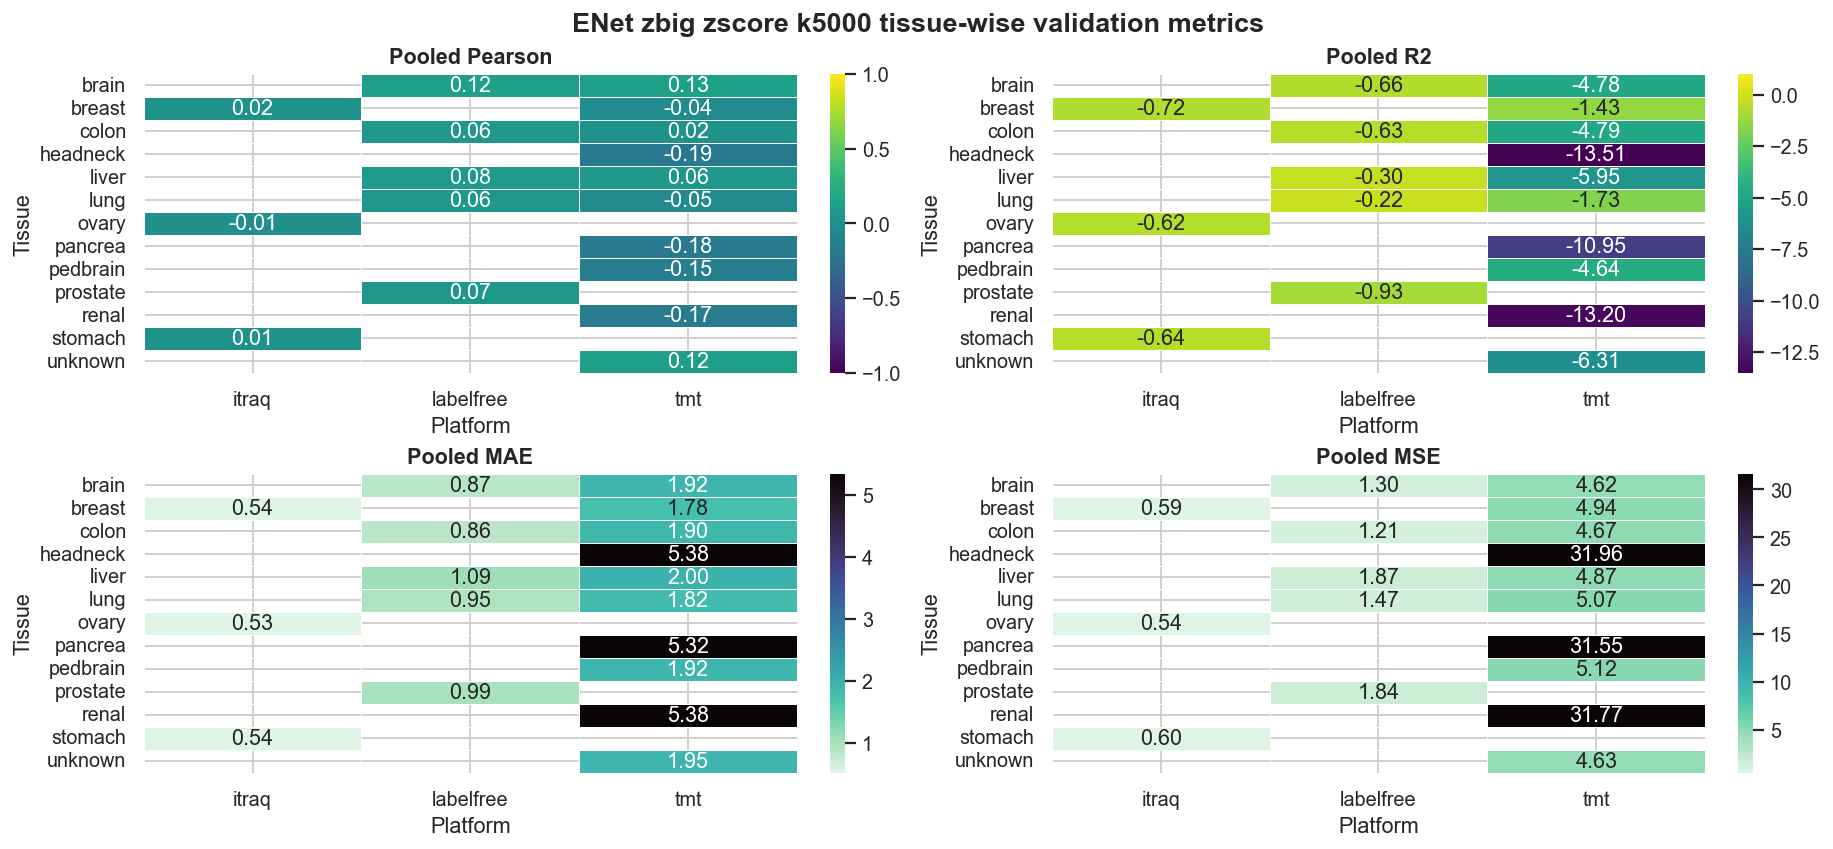

In [14]:
# ============================================================
# ENet zbig k5000 tissue-wise export for Xu comparison
# ============================================================

# This cell is restart-safe. It reloads the res_enet_zbig per-folder checkpoint
# if the in-memory res_enet_zbig result bundle is not available.
enet_zbig_export = export_enet_zbig_k5000_tissue_metrics(
    result_bundle=globals().get("res_enet_zbig"),
    datasets_arg=datasets,
    output_dir=OUTPUT_DIR,
    write_tissue_protein_metrics=SAVE_ENET_ZBIG_TISSUE_PROTEIN_METRICS,
)
enet_zbig_tissue_metrics = enet_zbig_export["tissue_metrics"]
enet_zbig_tissue_protein_metrics = enet_zbig_export["tissue_protein_metrics"]
enet_zbig_xu_format = enet_zbig_export["xu_format"]

print("\nThe ENet zbig k5000 CSV uses the same leading columns as Xu TableS6.")
display(enet_zbig_xu_format[[c for c in TABLES6_COLUMNS + ["source_folder", "run_label", "test_r2", "test_mse"] if c in enet_zbig_xu_format.columns]].head(20))

# Compact visual quality check for the exported tissue-wise ENet metrics.
if not enet_zbig_tissue_metrics.empty:
    plot_df = enet_zbig_tissue_metrics.copy()
    metric_specs = [
        ("pearson_corr", "Pooled Pearson", "viridis", -1, 1),
        ("r2", "Pooled R2", "viridis", None, 1),
        ("mae", "Pooled MAE", "mako_r", None, None),
        ("mse", "Pooled MSE", "mako_r", None, None),
    ]
    fig_h = max(6, 0.34 * plot_df["tissue_for_xu"].nunique() + 2.0)
    fig, axes = plt.subplots(2, 2, figsize=(14, fig_h), constrained_layout=True)
    fig.suptitle("ENet zbig zscore k5000 tissue-wise validation metrics", fontsize=15, fontweight="bold")
    for ax, (metric, title, cmap, vmin, vmax) in zip(axes.ravel(), metric_specs):
        pivot = plot_df.pivot_table(index="tissue_for_xu", columns="platform_for_xu", values=metric, aggfunc="median")
        if metric in {"mae", "mse"}:
            vals = pivot.to_numpy().ravel()
            vals = vals[np.isfinite(vals)]
            vmax_plot = np.nanpercentile(vals, 90) if len(vals) else None
            sns.heatmap(pivot, ax=ax, cmap=cmap, linewidths=0.4, linecolor="white", annot=True, fmt=".2f", vmax=vmax_plot)
        else:
            sns.heatmap(pivot, ax=ax, cmap=cmap, linewidths=0.4, linecolor="white", annot=True, fmt=".2f", vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.set_xlabel("Platform")
        ax.set_ylabel("Tissue")
    plt.show()

sync_utils_globals()


## 7. Clean summary prints

In [15]:
try:
    metrics_by_protein
except NameError:
    metrics_by_protein, feature_coverage = refresh_combined_metric_tables()

if metrics_by_protein.empty:
    print("No protein-level metrics available yet. Run at least one evaluation cell first.")
else:
    print("Model rows by dataset and run label")
    display(
        metrics_by_protein.groupby(["dataset", "run_label"])
        .agg(
            proteins=("protein", "nunique"),
            pearson_nonmissing=("test_pearson_corr", lambda s: s.notna().sum()),
            median_pearson=("test_pearson_corr", "median"),
            median_cosine=("test_cosine_similarity", "median"),
            median_mse=("test_mse", "median"),
        )
        .reset_index()
        .sort_values(["dataset", "median_pearson"], ascending=[True, False])
    )

    print("\nFeature coverage summary")
    display(
        metrics_by_protein.groupby("run_label")
        .agg(
            median_missing_fraction=("missing_feature_fraction", "median"),
            max_missing_fraction=("missing_feature_fraction", "max"),
            median_selected_features=("selected_feature_count", "median"),
        )
        .sort_values("median_missing_fraction")
    )

Model rows by dataset and run label


,dataset,run_label,proteins,pearson_nonmissing,median_pearson,median_cosine,median_mse
8,LabelFree,results_enet | zscore | fast | k500,25,25,0.230461,2.181921e-01,8.739874e-01
12,LabelFree,results_xgb | qbin50 | tiny | k50,1,1,0.190509,3.784419e-01,3.640514e-01
3,LabelFree,results_enet | none | fast | k500,25,25,0.163995,1.846074e-02,2.804287e+00
6,LabelFree,results_enet | unknown | fast | k500,25,24,0.128187,6.359879e-02,3.535593e+01
4,LabelFree,results_enet | ranking | fast | k2000,2155,2135,0.113368,5.349470e-02,3.361032e+07
7,LabelFree,results_enet | zscore | fast | k2000,2155,2138,0.103802,9.669994e-02,1.030591e+00
14,LabelFree,results_xgb | zscore | fast | k2000,2155,2155,0.100798,5.271784e-02,1.156633e+00
1,LabelFree,res_xgb_zbig | zscore | current | k5000,2155,2155,0.099510,5.179310e-02,1.155184e+00
0,LabelFree,res_enet_zbig | zscore | fast | k5000,2155,2141,0.099160,9.242556e-02,1.057716e+00
11,LabelFree,results_xgb | qbin50 | fast | k2000,2155,2155,0.087238,4.647627e-02,1.181905e+00



Feature coverage summary


,median_missing_fraction,max_missing_fraction,median_selected_features
run_label,,,
results_xgb | none | tiny | k50,0.1200,0.1200,50.0
results_enet | unknown | fast | k500,0.1860,0.2800,500.0
results_enet | unknown | fast | k2000,0.2795,0.4840,2000.0
results_enet | none | fast | k500,0.2860,0.4880,500.0
results_enet | none | fast | k2000,0.3295,0.5015,2000.0
results_xgb | none | fast | k2000,0.3660,0.5210,2000.0
results_enet | ranking | fast | k2000,0.3795,0.4975,2000.0
res_enet_zbig | zscore | fast | k5000,NaN,NaN,5000.0
res_xgb_zbig | zscore | current | k5000,NaN,NaN,5000.0


## 8. Visualizations: protein-level external validation performance

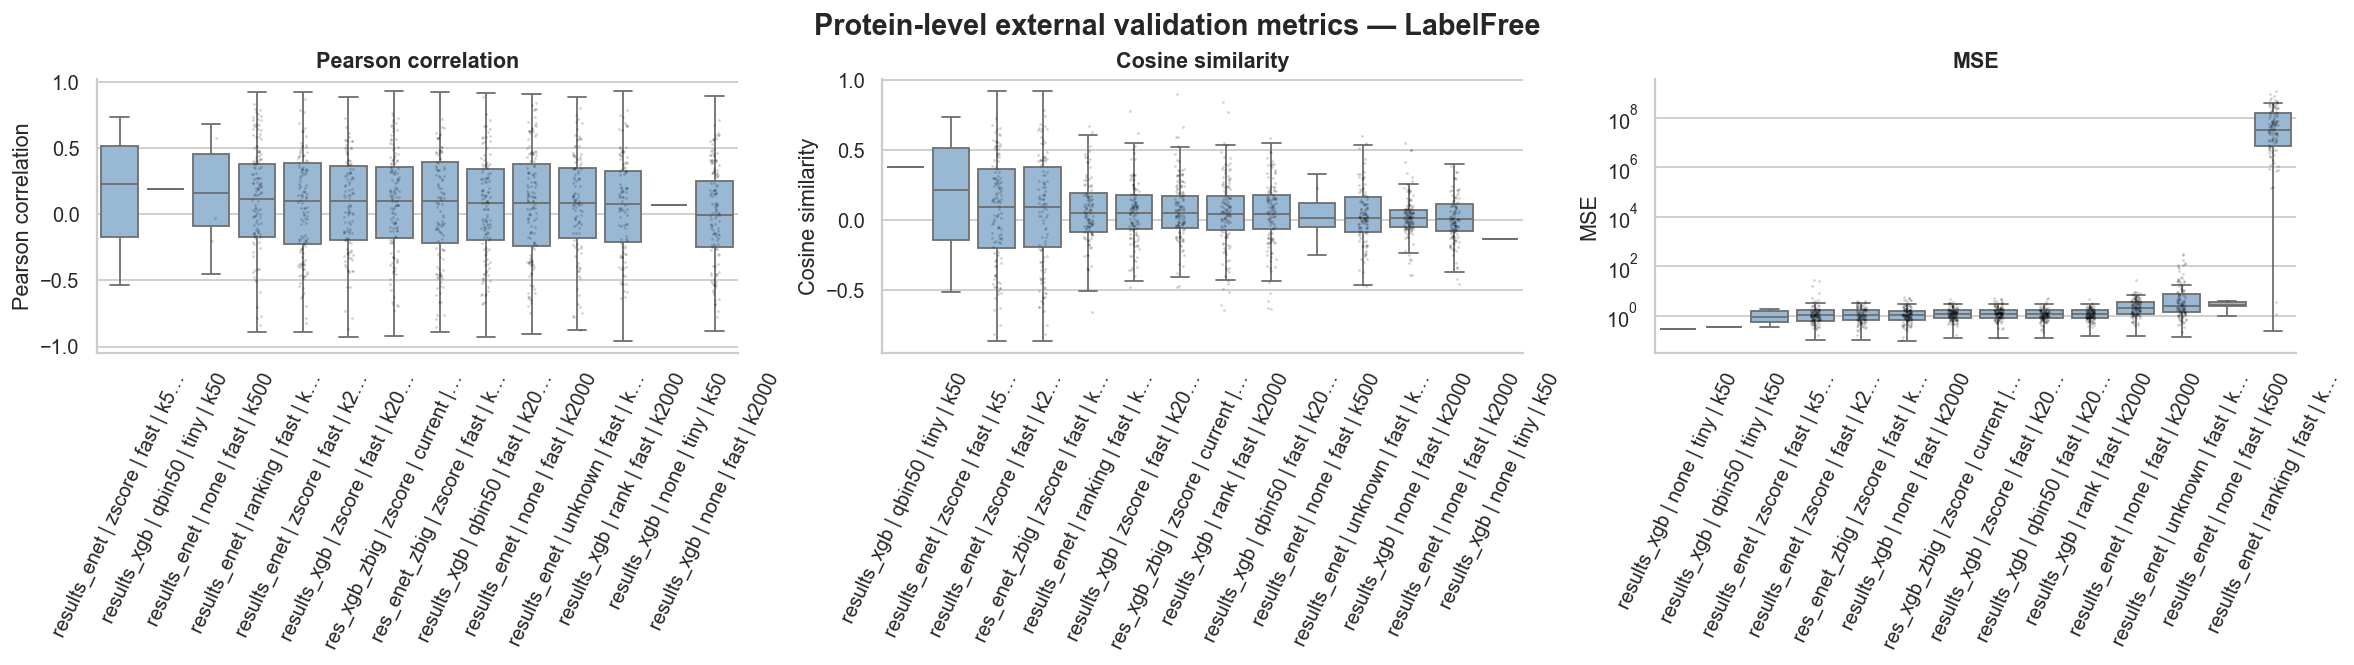

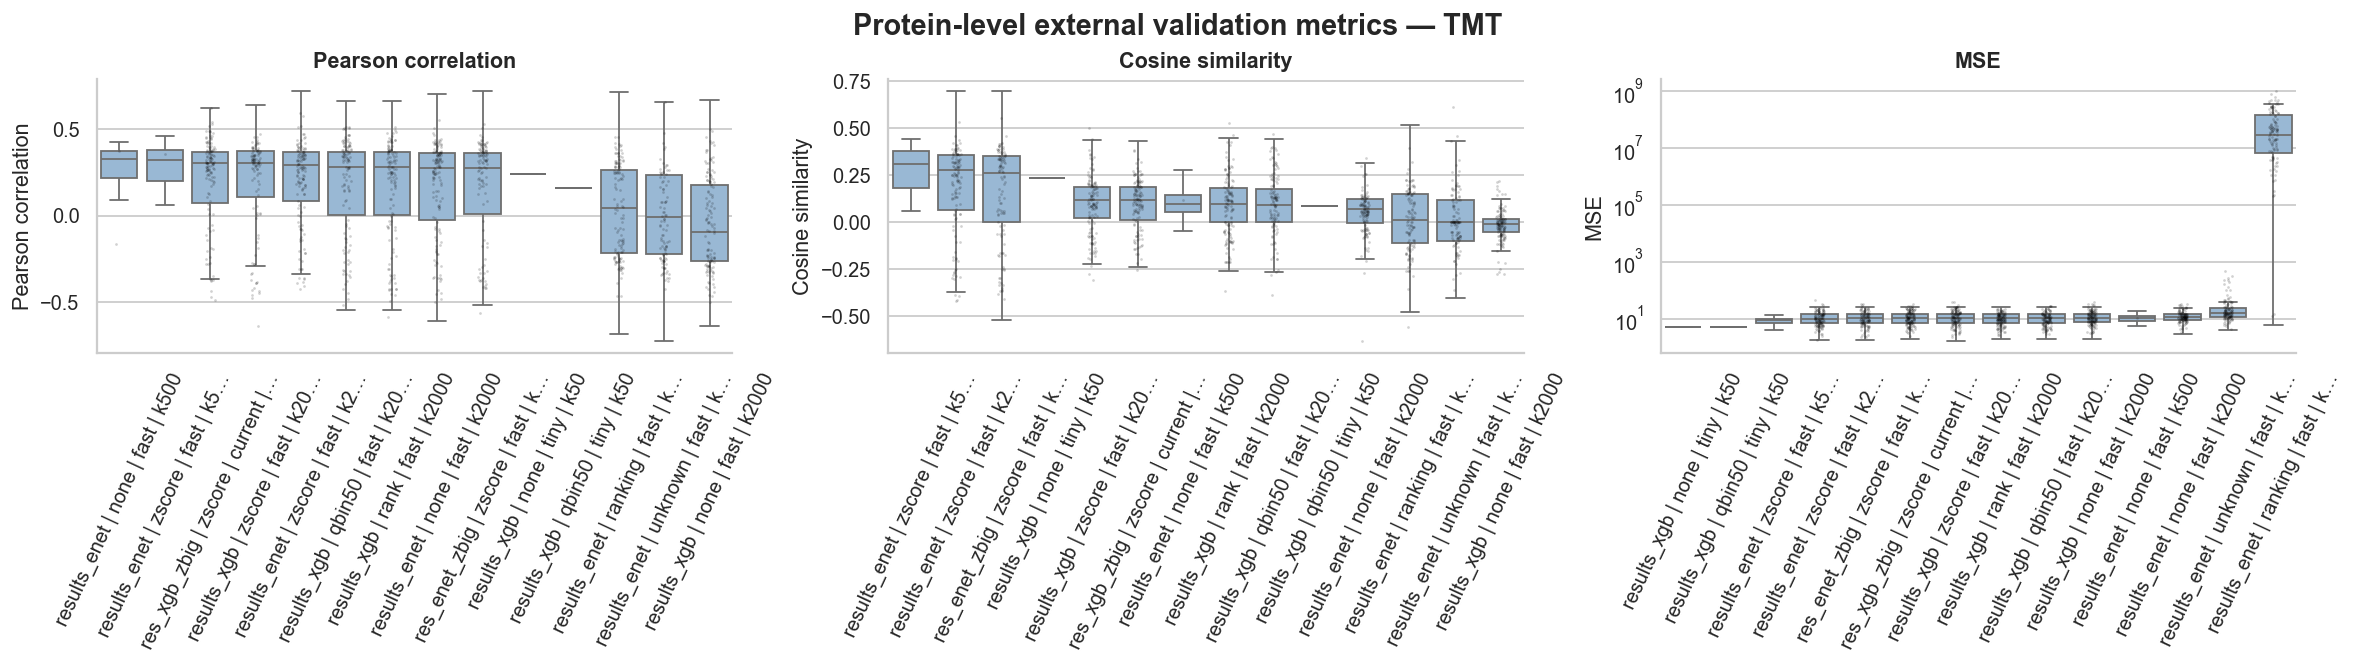

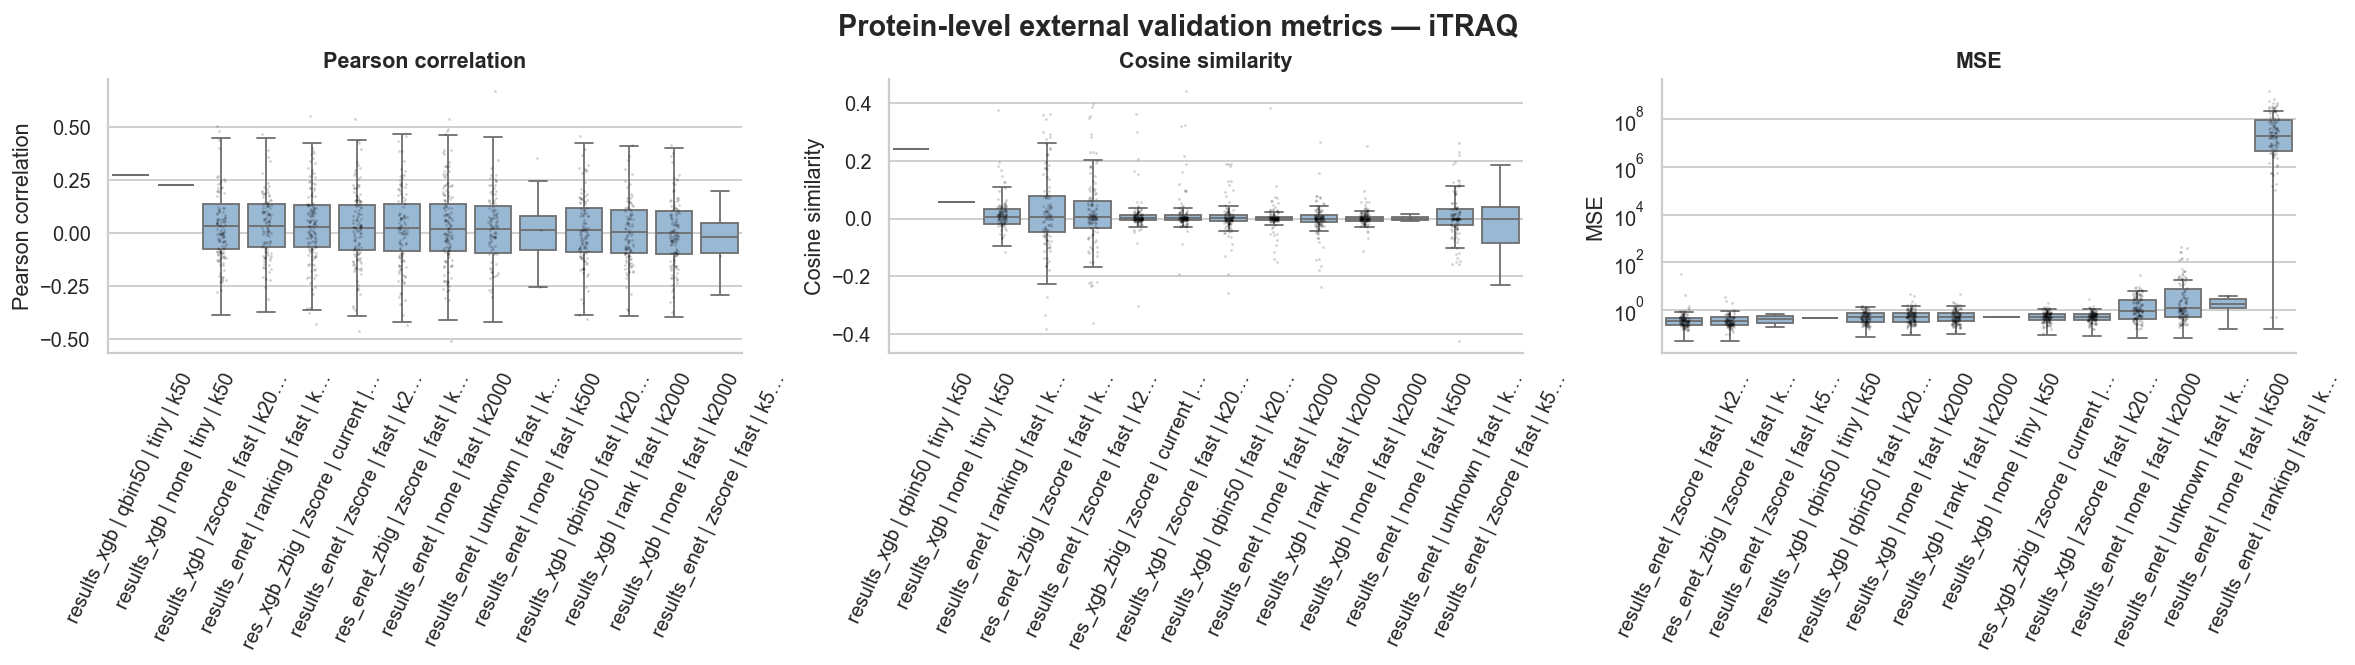

In [16]:
try:
    metrics_by_protein
except NameError:
    metrics_by_protein, feature_coverage = refresh_combined_metric_tables()

if metrics_by_protein.empty:
    print("No protein-level metrics available for plotting yet.")
else:
    plot_df = metrics_by_protein.copy()
    plot_df["run_label_short"] = plot_df["run_label"].map(compact_label)

    metric_specs = [
        ("test_pearson_corr", "Pearson correlation", None),
        ("test_cosine_similarity", "Cosine similarity", None),
        ("test_mse", "MSE", "log"),
    ]

    for dataset_name in sorted(plot_df["dataset"].dropna().unique()):
        sub = plot_df[plot_df["dataset"] == dataset_name].copy()
        if sub.empty:
            continue

        fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
        fig.suptitle(f"Protein-level external validation metrics — {dataset_name}", fontsize=16, fontweight="bold")

        for ax, (metric, label, scale) in zip(axes, metric_specs):
            data = sub.dropna(subset=[metric]).copy()
            if data.empty:
                ax.set_title(f"{label}\n(no valid values)")
                ax.axis("off")
                continue
            order = data.groupby("run_label_short")[metric].median().sort_values(ascending=(metric == "test_mse")).index.tolist()
            sns.boxplot(data=data, x="run_label_short", y=metric, order=order, ax=ax, color="#8FB8DE", showfliers=False)
            sns.stripplot(data=data.sample(min(len(data), 1200), random_state=42), x="run_label_short", y=metric, order=order, ax=ax, color="black", size=1.5, alpha=0.18)
            ax.set_title(label)
            ax.set_xlabel("")
            ax.set_ylabel(label)
            ax.tick_params(axis="x", rotation=65)
            if scale == "log":
                ax.set_yscale("log")

        plt.show()

## 9. Visualizations: tissue-level performance

In [ ]:
try:
    metrics_by_tissue
except NameError:
    if METRICS_TISSUE_CSV.exists():
        metrics_by_tissue = pd.read_csv(METRICS_TISSUE_CSV)
    elif "enet_zbig_tissue_metrics" in globals():
        metrics_by_tissue = enet_zbig_tissue_metrics.copy()
    else:
        metrics_by_tissue = pd.DataFrame()

if metrics_by_tissue.empty:
    print("No tissue-level metrics available for plotting yet.")
    print("For all-model tissue heatmaps, set BUILD_ALL_MODEL_TISSUE_METRICS=True and run the refresh cell.")
else:
    tissue_plot = metrics_by_tissue.copy()
    if "run_label" not in tissue_plot.columns and "source_model" in tissue_plot.columns:
        tissue_plot["run_label"] = tissue_plot["source_model"]
    if "tissue" not in tissue_plot.columns and "tissue_for_xu" in tissue_plot.columns:
        tissue_plot["tissue"] = tissue_plot["tissue_for_xu"]
    if "dataset" not in tissue_plot.columns and "platform_for_xu" in tissue_plot.columns:
        tissue_plot["dataset"] = tissue_plot["platform_for_xu"]
    tissue_plot["run_label_short"] = tissue_plot["run_label"].map(compact_label)

    for dataset_name in sorted(tissue_plot["dataset"].dropna().unique()):
        sub_ds = tissue_plot[tissue_plot["dataset"] == dataset_name].copy()
        if sub_ds.empty:
            continue

        tissue_counts = sub_ds.groupby("tissue")["n_prediction_pairs"].max().sort_values(ascending=False)
        keep_tissues = tissue_counts.head(20).index.tolist()
        sub_ds = sub_ds[sub_ds["tissue"].isin(keep_tissues)].copy()

        fig, axes = plt.subplots(1, 3, figsize=(20, max(5, 0.35 * len(keep_tissues))), constrained_layout=True)
        fig.suptitle(f"Tissue-level external validation performance — {dataset_name}", fontsize=16, fontweight="bold")

        heatmap_specs = [
            ("test_pearson_corr", "Pearson", "viridis", True),
            ("test_cosine_similarity", "Cosine", "viridis", True),
            ("test_mse", "MSE", "mako_r", False),
        ]

        for ax, (metric, title, cmap, higher) in zip(axes, heatmap_specs):
            if metric not in sub_ds.columns:
                ax.axis("off")
                ax.set_title(f"{title} missing")
                continue
            pivot = sub_ds.pivot_table(index="tissue", columns="run_label_short", values=metric, aggfunc="median")
            if metric == "test_mse":
                vals = pivot.to_numpy().ravel()
                vals = vals[np.isfinite(vals)]
                vmax = np.nanpercentile(vals, 90) if len(vals) else None
                sns.heatmap(pivot, ax=ax, cmap=cmap, linewidths=0.4, linecolor="white", cbar_kws={"label": title}, vmax=vmax)
            else:
                sns.heatmap(pivot, ax=ax, cmap=cmap, linewidths=0.4, linecolor="white", cbar_kws={"label": title}, vmin=-1, vmax=1)
            ax.set_title(title)
            ax.set_xlabel("")
            ax.set_ylabel("Tissue")

        plt.show()

## 10. Save-note for downstream notebooks

In [ ]:
print("Saved files for downstream notebooks:")
print("-", METRICS_PROTEIN_CSV)
print("-", METRICS_TISSUE_CSV)
print("-", METRICS_TISSUE_XU_FORMAT_CSV, "(same leading columns as Xu TableS6)")
print("-", METRICS_TISSUE_PROTEIN_CSV, "(created when SAVE_COMBINED_TISSUE_PROTEIN_METRICS=True)")
print("-", MODEL_INVENTORY_CSV)
print("-", FEATURE_COVERAGE_CSV)
print("-", ENET_ZBIG_TISSUE_CSV)
print("-", ENET_ZBIG_TISSUE_PROTEIN_CSV)
print("-", ENET_ZBIG_XU_FORMAT_CSV)
print("\nPer-folder prediction and tissue checkpoints are saved in:", OUTPUT_DIR.resolve())
print("Full combined predictions are skipped by default to avoid the old bottleneck.")
print("Set BUILD_FULL_COMBINED_PREDICTIONS=True and rerun the refresh cell only if eval_predictions_long.parquet is needed.")